In [ ]:
!pip install ultralytics -q

from google.colab import drive
drive.mount('/content/drive')

import torch
print(f"GPU  : {torch.cuda.get_device_name(0)}")
print(f"VRAM : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 64.2 MB/s eta 0:00:00
Mounted at /content/drive
GPU  : Tesla T4
VRAM : 15.6 GB


In [ ]:
import os, glob, json

# Adjust this path to match your Drive structure
DENTEX_PATH = '/content/drive/MyDrive/training_data/quadrant_enumeration'

print("Contents:")
for root, dirs, files in os.walk(DENTEX_PATH):
    depth = root.replace(DENTEX_PATH, '').count(os.sep)
    if depth > 2:
        continue
    indent = '  ' * depth
    print(indent + os.path.basename(root) + f'/  ({len(files)} files)')

json_files = glob.glob(f'{DENTEX_PATH}/**/*.json', recursive=True)
print(f"\nJSON annotation files: {json_files}")

Contents:
quadrant_enumeration/  (1 files)
  xrays/  (634 files)

JSON annotation files: ['/content/drive/MyDrive/training_data/quadrant_enumeration/train_quadrant_enumeration.json']


In [ ]:
# Inspect the actual structure — REQUIRED before converting
with open(json_files[0]) as f:
    data = json.load(f)

print("Top-level keys:", list(data.keys()))
print(f"\nTotal images: {len(data.get('images', []))}")
print(f"Total annotations: {len(data.get('annotations', []))}")

print(f"\nSample image entry:")
print(data['images'][0])

print(f"\nSample annotation entry:")
print(data['annotations'][0])

print(f"\nCategory definitions:")
for key in data.keys():
    if 'categor' in key.lower():
        print(f"  {key}:")
        for c in data[key]:
            print(f"    {c}")

Top-level keys: ['images', 'annotations', 'categories_1', 'categories_2']

Total images: 634
Total annotations: 18095

Sample image entry:
{'height': 1316, 'width': 2710, 'id': 1, 'file_name': 'train_283.png'}

Sample annotation entry:
{'iscrowd': 0, 'image_id': 1, 'bbox': [1283.3333333333333, 459.25925925925924, 100.0, 262.03703703703707], 'segmentation': [[1366, 459, 1383, 662, 1380, 716, 1295, 721, 1288, 659, 1283, 464]], 'id': 1, 'area': 22904, 'category_id_1': 0, 'category_id_2': 0}

Category definitions:
  categories_1:
    {'id': 0, 'name': 1, 'supercategory': 1}
    {'id': 1, 'name': 2, 'supercategory': 2}
    {'id': 2, 'name': 3, 'supercategory': 3}
    {'id': 3, 'name': 4, 'supercategory': 4}
  categories_2:
    {'id': 0, 'name': '1', 'supercategory': '1'}
    {'id': 1, 'name': '2', 'supercategory': '2'}
    {'id': 2, 'name': '3', 'supercategory': '3'}
    {'id': 3, 'name': '4', 'supercategory': '4'}
    {'id': 4, 'name': '5', 'supercategory': '5'}
    {'id': 5, 'name': '6', 

In [ ]:
# Quick check — show full annotation keys
print("Full annotation keys:", list(data['annotations'][0].keys()))
print("\nFull sample annotation:")
print(data['annotations'][0])

Full annotation keys: ['iscrowd', 'image_id', 'bbox', 'segmentation', 'id', 'area', 'category_id_1', 'category_id_2']

Full sample annotation:
{'iscrowd': 0, 'image_id': 1, 'bbox': [1283.3333333333333, 459.25925925925924, 100.0, 262.03703703703707], 'segmentation': [[1366, 459, 1383, 662, 1380, 716, 1295, 721, 1288, 659, 1283, 464]], 'id': 1, 'area': 22904, 'category_id_1': 0, 'category_id_2': 0}


In [ ]:
import os, json, shutil
from pathlib import Path

FDI_CLASSES = [
    '11','12','13','14','15','16','17','18',
    '21','22','23','24','25','26','27','28',
    '31','32','33','34','35','36','37','38',
    '41','42','43','44','45','46','47','48',
]
fdi_to_idx = {fdi: i for i, fdi in enumerate(FDI_CLASSES)}

def quadrant_enum_to_fdi(quadrant_id, enum_id):
    """
    quadrant_id (0-3) -> FDI quadrant digit (1-4)
    enum_id (0-7)     -> FDI tooth digit (1-8)
    Your categories_1: id 0='1', 1='2', 2='3', 3='4'  (already matches FDI quadrant numbering)
    Your categories_2: id 0='1', 1='2', ..., 7='8'    (already matches FDI tooth numbering)
    """
    quadrant_digit = str(quadrant_id + 1)   # 0->1, 1->2, 2->3, 3->4
    tooth_digit    = str(enum_id + 1)       # 0->1, 1->2, ..., 7->8
    return quadrant_digit + tooth_digit


def convert_dentex_to_yolo(json_path, images_root, output_root):
    with open(json_path) as f:
        data = json.load(f)

    images = {img['id']: img for img in data['images']}
    os.makedirs(f"{output_root}/images", exist_ok=True)
    os.makedirs(f"{output_root}/labels", exist_ok=True)

    anns_by_image = {}
    for ann in data['annotations']:
        anns_by_image.setdefault(ann['image_id'], []).append(ann)

    converted, skipped, copy_failed = 0, 0, 0

    for img_id, anns in anns_by_image.items():
        img_info = images[img_id]
        W, H = img_info['width'], img_info['height']
        fname = img_info['file_name']
        stem  = Path(fname).stem

        lines = []
        for ann in anns:
            if 'category_id_1' not in ann or 'category_id_2' not in ann:
                skipped += 1
                continue

            quadrant_id = ann['category_id_1']
            enum_id     = ann['category_id_2']
            fdi         = quadrant_enum_to_fdi(quadrant_id, enum_id)
            cls_idx     = fdi_to_idx[fdi]

            x, y, w, h = ann['bbox']
            xc = (x + w/2) / W
            yc = (y + h/2) / H
            wn = w / W
            hn = h / H

            # Clamp to valid range
            xc, yc = max(0,min(1,xc)), max(0,min(1,yc))
            wn, hn = max(0,min(1,wn)), max(0,min(1,hn))

            lines.append(f"{cls_idx} {xc:.6f} {yc:.6f} {wn:.6f} {hn:.6f}")

        if lines:
            with open(f"{output_root}/labels/{stem}.txt", 'w') as f:
                f.write('\n'.join(lines))

            src_img = os.path.join(images_root, fname)
            if os.path.exists(src_img):
                shutil.copy(src_img, f"{output_root}/images/{fname}")
                converted += 1
            else:
                copy_failed += 1

    print(f"Converted     : {converted} images")
    print(f"Skipped (anns): {skipped} annotations (missing category fields)")
    print(f"Image not found: {copy_failed}")
    return converted


# Find where the actual image files live
import glob
img_search = glob.glob(f"{DENTEX_PATH}/**/train_283.png", recursive=True)
print(f"Found sample image at: {img_search}")

IMAGES_ROOT = os.path.dirname(img_search[0]) if img_search else DENTEX_PATH
print(f"Using images root: {IMAGES_ROOT}")

Found sample image at: ['/content/drive/MyDrive/training_data/quadrant_enumeration/xrays/train_283.png']
Using images root: /content/drive/MyDrive/training_data/quadrant_enumeration/xrays


In [ ]:
# Run the conversion
ALL_DATA = '/content/dentex_yolo_all'

n_converted = convert_dentex_to_yolo(
    json_path   = json_files[0],
    images_root = IMAGES_ROOT,
    output_root = ALL_DATA,
)

Converted     : 634 images
Skipped (anns): 0 annotations (missing category fields)
Image not found: 0


In [ ]:
# Verify — check class IDs are all valid (0-31)
import glob

label_files = glob.glob(f'{ALL_DATA}/labels/*.txt')
all_classes = set()
for lf in label_files:
    with open(lf) as f:
        for line in f:
            all_classes.add(int(line.split()[0]))

print(f"Label files: {len(label_files)}")
print(f"Unique classes found: {sorted(all_classes)}")
print(f"Expected: 0 to 31")
print(f"Valid: {all(0<=c<=31 for c in all_classes)}")

Label files: 634
Unique classes found: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31]
Expected: 0 to 31
Valid: True


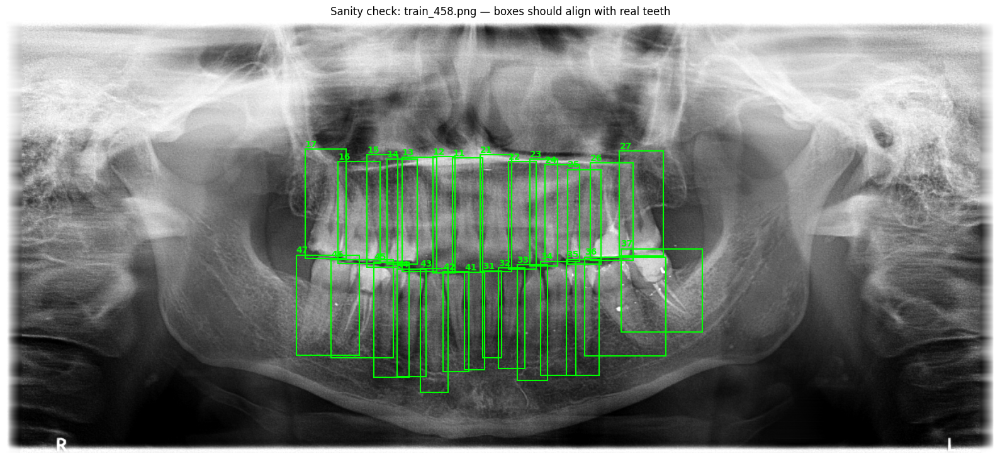

In [ ]:
# Visual sanity check
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches

sample_img = glob.glob(f"{ALL_DATA}/images/*")[0]
stem = os.path.splitext(os.path.basename(sample_img))[0]
sample_lbl = f"{ALL_DATA}/labels/{stem}.txt"

img = cv2.cvtColor(cv2.imread(sample_img), cv2.COLOR_BGR2RGB)
H, W = img.shape[:2]

fig, ax = plt.subplots(figsize=(16, 8))
ax.imshow(img, cmap='gray')

with open(sample_lbl) as f:
    for line in f:
        p = line.strip().split()
        cls_id = int(p[0])
        xc, yc, bw, bh = map(float, p[1:5])
        x1 = (xc - bw/2) * W
        y1 = (yc - bh/2) * H
        ax.add_patch(patches.Rectangle(
            (x1, y1), bw*W, bh*H,
            linewidth=1.5, edgecolor='lime', facecolor='none'))
        ax.text(x1, max(0,y1-8), FDI_CLASSES[cls_id],
                color='lime', fontsize=10, fontweight='bold')

ax.set_title(f"Sanity check: {os.path.basename(sample_img)} — boxes should align with real teeth")
ax.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
import random, shutil

ALL_DATA = '/content/dentex_yolo_all'
SPLIT_OUT = '/content/dentex_final'

# Run conversion (update paths once Stage 2 confirms structure)
convert_dentex_to_yolo(
    json_path   = json_files[0],
    images_root = img_folders[0] if img_folders else DENTEX_PATH,
    output_root = ALL_DATA,
)

# 90/10 train/valid split
all_imgs = glob.glob(f"{ALL_DATA}/images/*")
random.shuffle(all_imgs)
split_point = int(len(all_imgs) * 0.9)
train_imgs = all_imgs[:split_point]
valid_imgs = all_imgs[split_point:]

for split, img_list in [('train', train_imgs), ('valid', valid_imgs)]:
    os.makedirs(f"{SPLIT_OUT}/{split}/images", exist_ok=True)
    os.makedirs(f"{SPLIT_OUT}/{split}/labels", exist_ok=True)
    for img_path in img_list:
        stem = os.path.splitext(os.path.basename(img_path))[0]
        lbl_path = f"{ALL_DATA}/labels/{stem}.txt"
        shutil.copy(img_path, f"{SPLIT_OUT}/{split}/images/")
        if os.path.exists(lbl_path):
            shutil.copy(lbl_path, f"{SPLIT_OUT}/{split}/labels/")

print(f"Train: {len(train_imgs)} images")
print(f"Valid: {len(valid_imgs)} images")

NameError: name 'img_folders' is not defined

In [ ]:
import os, glob

DENTEX_PATH  = '/content/drive/MyDrive/training_data/quadrant_enumeration'
IMAGES_ROOT  = f"{DENTEX_PATH}/xrays"
JSON_PATH    = f"{DENTEX_PATH}/train_quadrant_enumeration.json"

# Verify these exist
print("Images folder exists:", os.path.exists(IMAGES_ROOT))
print("JSON file exists    :", os.path.exists(JSON_PATH))
print("Sample images:", os.listdir(IMAGES_ROOT)[:5])

Images folder exists: True
JSON file exists    : True
Sample images: ['train_412.png', 'train_184.png', 'train_351.png', 'train_23.png', 'train_200.png']


In [ ]:
ALL_DATA = '/content/dentex_yolo_all'

n_converted = convert_dentex_to_yolo(
    json_path   = JSON_PATH,
    images_root = IMAGES_ROOT,
    output_root = ALL_DATA,
)

Converted     : 634 images
Skipped (anns): 0 annotations (missing category fields)
Image not found: 0


In [ ]:
import json, shutil
from pathlib import Path

FDI_CLASSES = [
    '11','12','13','14','15','16','17','18',
    '21','22','23','24','25','26','27','28',
    '31','32','33','34','35','36','37','38',
    '41','42','43','44','45','46','47','48',
]
fdi_to_idx = {fdi: i for i, fdi in enumerate(FDI_CLASSES)}

def quadrant_enum_to_fdi(quadrant_id, enum_id):
    quadrant_digit = str(quadrant_id + 1)
    tooth_digit    = str(enum_id + 1)
    return quadrant_digit + tooth_digit

def convert_dentex_to_yolo(json_path, images_root, output_root):
    with open(json_path) as f:
        data = json.load(f)

    images = {img['id']: img for img in data['images']}
    os.makedirs(f"{output_root}/images", exist_ok=True)
    os.makedirs(f"{output_root}/labels", exist_ok=True)

    anns_by_image = {}
    for ann in data['annotations']:
        anns_by_image.setdefault(ann['image_id'], []).append(ann)

    converted, skipped, copy_failed = 0, 0, 0

    for img_id, anns in anns_by_image.items():
        img_info = images[img_id]
        W, H = img_info['width'], img_info['height']
        fname = img_info['file_name']
        stem  = Path(fname).stem

        lines = []
        for ann in anns:
            if 'category_id_1' not in ann or 'category_id_2' not in ann:
                skipped += 1
                continue

            quadrant_id = ann['category_id_1']
            enum_id     = ann['category_id_2']
            fdi         = quadrant_enum_to_fdi(quadrant_id, enum_id)
            cls_idx     = fdi_to_idx[fdi]

            x, y, w, h = ann['bbox']
            xc = max(0, min(1, (x + w/2) / W))
            yc = max(0, min(1, (y + h/2) / H))
            wn = max(0, min(1, w / W))
            hn = max(0, min(1, h / H))

            lines.append(f"{cls_idx} {xc:.6f} {yc:.6f} {wn:.6f} {hn:.6f}")

        if lines:
            with open(f"{output_root}/labels/{stem}.txt", 'w') as f:
                f.write('\n'.join(lines))

            src_img = os.path.join(images_root, fname)
            if os.path.exists(src_img):
                shutil.copy(src_img, f"{output_root}/images/{fname}")
                converted += 1
            else:
                copy_failed += 1

    print(f"Converted      : {converted} images")
    print(f"Skipped (anns) : {skipped} annotations (missing category fields)")
    print(f"Image not found: {copy_failed}")
    return converted

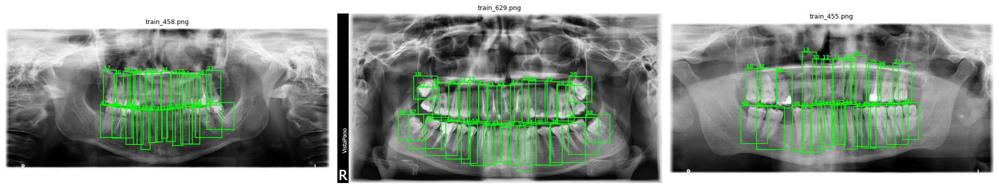

In [ ]:
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import os

sample_imgs = glob.glob(f"{ALL_DATA}/images/*")[:3]

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

for ax, sample_img in zip(axes, sample_imgs):
    stem = os.path.splitext(os.path.basename(sample_img))[0]
    sample_lbl = f"{ALL_DATA}/labels/{stem}.txt"

    img = cv2.cvtColor(cv2.imread(sample_img), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    ax.imshow(img, cmap='gray')

    if os.path.exists(sample_lbl):
        with open(sample_lbl) as f:
            for line in f:
                p = line.strip().split()
                cls_id = int(p[0])
                xc, yc, bw, bh = map(float, p[1:5])
                x1 = (xc - bw/2) * W
                y1 = (yc - bh/2) * H
                ax.add_patch(patches.Rectangle(
                    (x1, y1), bw*W, bh*H,
                    linewidth=1.2, edgecolor='lime', facecolor='none'))
                ax.text(x1, max(0,y1-6), FDI_CLASSES[cls_id],
                        color='lime', fontsize=8, fontweight='bold')

    ax.set_title(os.path.basename(sample_img), fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
import random, shutil, os, glob

SPLIT_OUT = '/content/dentex_final'

all_imgs = glob.glob(f"{ALL_DATA}/images/*")
random.seed(42)
random.shuffle(all_imgs)

split_point = int(len(all_imgs) * 0.9)
train_imgs  = all_imgs[:split_point]
valid_imgs  = all_imgs[split_point:]

for split, img_list in [('train', train_imgs), ('valid', valid_imgs)]:
    os.makedirs(f"{SPLIT_OUT}/{split}/images", exist_ok=True)
    os.makedirs(f"{SPLIT_OUT}/{split}/labels", exist_ok=True)
    for img_path in img_list:
        stem = os.path.splitext(os.path.basename(img_path))[0]
        lbl_path = f"{ALL_DATA}/labels/{stem}.txt"
        shutil.copy(img_path, f"{SPLIT_OUT}/{split}/images/")
        if os.path.exists(lbl_path):
            shutil.copy(lbl_path, f"{SPLIT_OUT}/{split}/labels/")

print(f"Train: {len(train_imgs)} images")
print(f"Valid: {len(valid_imgs)} images")

Train: 570 images
Valid: 64 images


In [ ]:
import yaml

final_cfg = {
    'path' : SPLIT_OUT,
    'train': 'train/images',
    'val'  : 'valid/images',
    'nc'   : 32,
    'names': FDI_CLASSES,
}

YAML_PATH = f"{SPLIT_OUT}/data.yaml"
with open(YAML_PATH, 'w') as f:
    yaml.dump(final_cfg, f)

print(f"YAML saved to: {YAML_PATH}")
print(final_cfg)

YAML saved to: /content/dentex_final/data.yaml
{'path': '/content/dentex_final', 'train': 'train/images', 'val': 'valid/images', 'nc': 32, 'names': ['11', '12', '13', '14', '15', '16', '17', '18', '21', '22', '23', '24', '25', '26', '27', '28', '31', '32', '33', '34', '35', '36', '37', '38', '41', '42', '43', '44', '45', '46', '47', '48']}


In [ ]:
import torch
from ultralytics import YOLO
print(f"GPU  : {torch.cuda.get_device_name(0)}")
print(f"VRAM : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
GPU  : Tesla T4
VRAM : 15.6 GB


In [ ]:
import torch
from ultralytics import YOLO

print(f"GPU  : {torch.cuda.get_device_name(0)}")
print(f"VRAM : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")

# Fresh start — pretrained ImageNet weights only, no fine-tuning from old runs
model = YOLO('yolov8n.pt')

model.train(
    data        = YAML_PATH,
    epochs      = 80,          # DENTEX has ~570 train images, needs more epochs than your old 3032-image set
    imgsz       = 640,
    batch       = 16,
    device      = 0,
    patience    = 20,

    project     = '/content/drive/MyDrive/dental_runs',
    name        = 'opg_dentex_v1',
    save_period = 5,

    hsv_h       = 0.01,
    hsv_s       = 0.2,
    hsv_v       = 0.6,
    fliplr      = 0.5,
    flipud      = 0.0,
    degrees     = 8.0,
    translate   = 0.15,
    scale       = 0.5,
    mosaic      = 0.5,
    mixup       = 0.1,

    optimizer   = 'AdamW',
    lr0         = 0.001,
    plots       = True,
    verbose     = True,
)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
GPU  : Tesla T4
VRAM : 15.6 GB
Ultralytics 8.4.78 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dentex_final/data.yaml, degrees=8.0, deterministic=True, device=0, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=80, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, fr

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7e353c62bb00>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,

In [ ]:
import glob, os
from datetime import datetime

runs = glob.glob('/content/drive/MyDrive/dental_runs/*/weights/best.pt')

print(f"{'Path':<75} {'Size (MB)':<12} {'Modified'}")
print("-" * 115)
for r in sorted(runs):
    size_mb = os.path.getsize(r) / 1e6
    mtime = datetime.fromtimestamp(os.path.getmtime(r)).strftime('%Y-%m-%d %H:%M')
    print(f"{r:<75} {size_mb:<12.1f} {mtime}")

Path                                                                        Size (MB)    Modified
-------------------------------------------------------------------------------------------------------------------


In [ ]:
from google.colab import files
from pathlib import Path

uploaded = files.upload()
img_path = list(uploaded.keys())[0]

# Simple single-pass prediction — no tiling, no WBF
res = model.predict(img_path, conf=0.25, iou=0.4, imgsz=1280, verbose=False)[0]

print(f"Detected {len(res.boxes)} teeth\n")
detected = []
for box in res.boxes:
    fdi  = FDI_CLASSES[int(box.cls)]
    conf = round(float(box.conf), 3)
    detected.append((fdi, conf))

detected.sort(key=lambda x: int(x[0]))
for fdi, conf in detected:
    print(f"  Tooth {fdi}  conf={conf}")

KeyboardInterrupt: 

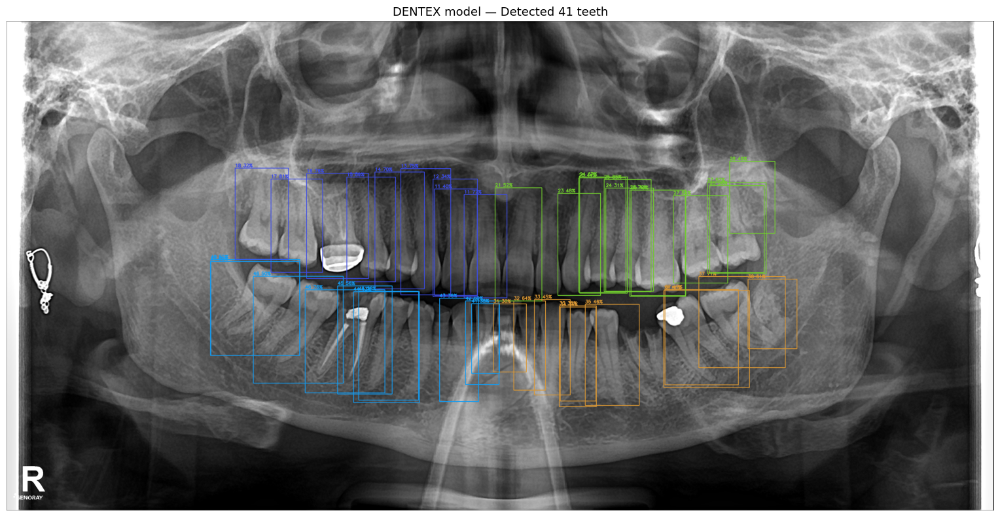

In [ ]:
# Visualize on original image
import cv2
import matplotlib.pyplot as plt

orig = cv2.imread(img_path)
quadrant_colors = {
    '1': (231, 76, 60), '2': (46, 204, 113),
    '3': (52, 152, 219), '4': (243, 156, 18),
}

result = orig.copy()
for box in res.boxes:
    x1, y1, x2, y2 = [int(v) for v in box.xyxy[0].tolist()]
    fdi = FDI_CLASSES[int(box.cls)]
    conf = float(box.conf)
    color = quadrant_colors[fdi[0]]
    cv2.rectangle(result, (x1,y1), (x2,y2), color, 2)
    label = f"{fdi} {conf:.0%}"
    cv2.putText(result, label, (x1, max(15,y1-5)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)

plt.figure(figsize=(18, 8))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title(f"DENTEX model — Detected {len(res.boxes)} teeth", fontsize=13)
plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
res = model.predict(
    img_path,
    conf  = 0.25,
    iou   = 0.5,      # increase from 0.4 — more aggressive duplicate removal
    imgsz = 1280,      # try larger inference size too
    verbose = False,
)[0]

print(f"Detected {len(res.boxes)} teeth")

Detected 43 teeth


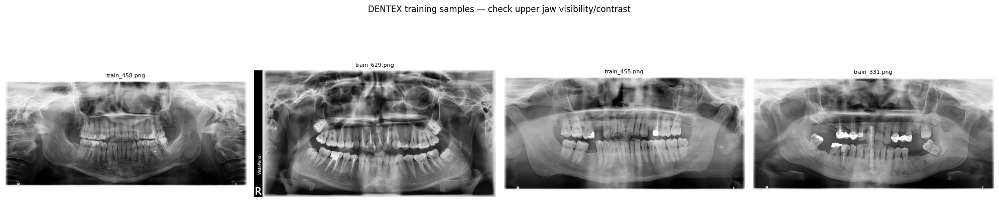

In [ ]:
# Quick check: does DENTEX training data actually contain upper-jaw examples
# with similar contrast to your real scanner?
import cv2
import matplotlib.pyplot as plt

sample_imgs = glob.glob(f"{SPLIT_OUT}/train/images/*")[:4]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, img_path_s in zip(axes, sample_imgs):
    img = cv2.cvtColor(cv2.imread(img_path_s), cv2.COLOR_BGR2RGB)
    ax.imshow(img, cmap='gray')
    ax.set_title(os.path.basename(img_path_s), fontsize=8)
    ax.axis('off')
plt.suptitle("DENTEX training samples — check upper jaw visibility/contrast")
plt.tight_layout()
plt.show()

In [ ]:
def quick_clahe(img_path):
    img = cv2.imread(img_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8,8))
    enhanced = clahe.apply(gray)
    return cv2.cvtColor(enhanced, cv2.COLOR_GRAY2BGR)

enhanced_img = quick_clahe(img_path)
cv2.imwrite('/content/enhanced_test.jpg', enhanced_img)

res2 = model.predict('/content/enhanced_test.jpg', conf=0.25, iou=0.5, imgsz=1280, verbose=False)[0]
print(f"With CLAHE: {len(res2.boxes)} teeth")

upper_count = sum(1 for b in res2.boxes if FDI_CLASSES[int(b.cls)][0] in ['1','2'])
print(f"Upper jaw teeth detected: {upper_count}")

With CLAHE: 42 teeth
Upper jaw teeth detected: 22


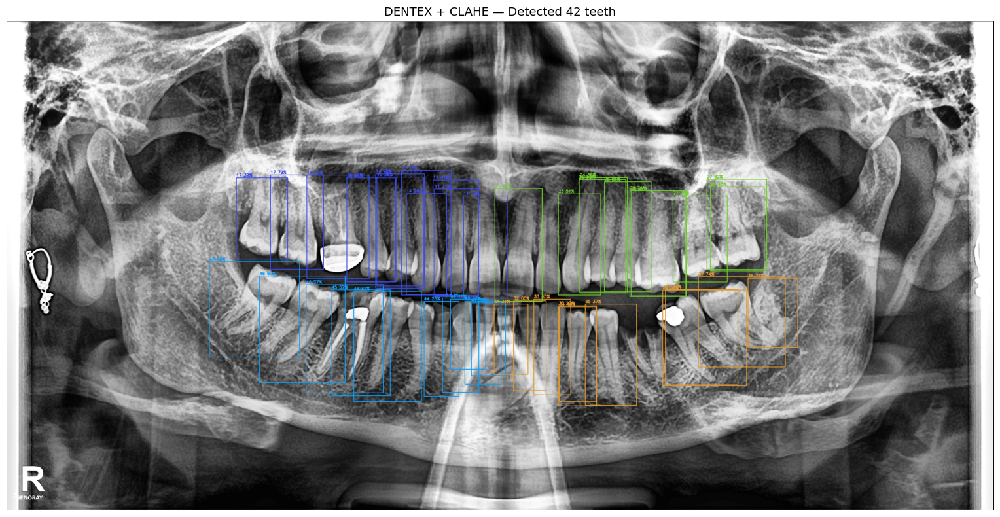

In [ ]:
import cv2
import matplotlib.pyplot as plt

orig = cv2.imread('/content/enhanced_test.jpg')
quadrant_colors = {
    '1': (231, 76, 60), '2': (46, 204, 113),
    '3': (52, 152, 219), '4': (243, 156, 18),
}

result = orig.copy()
for box in res2.boxes:
    x1, y1, x2, y2 = [int(v) for v in box.xyxy[0].tolist()]
    fdi  = FDI_CLASSES[int(box.cls)]
    conf = float(box.conf)
    color = quadrant_colors[fdi[0]]
    cv2.rectangle(result, (x1,y1), (x2,y2), color, 2)
    label = f"{fdi} {conf:.0%}"
    cv2.putText(result, label, (x1, max(15,y1-5)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.55, color, 2)

plt.figure(figsize=(18, 8))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title(f"DENTEX + CLAHE — Detected {len(res2.boxes)} teeth", fontsize=13)
plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
# Full breakdown by quadrant
print(f"\nDetected {len(res2.boxes)} teeth:\n")
detected = []
for box in res2.boxes:
    fdi  = FDI_CLASSES[int(box.cls)]
    conf = round(float(box.conf), 3)
    detected.append((fdi, conf))

detected.sort(key=lambda x: int(x[0]))
for fdi, conf in detected:
    print(f"  Tooth {fdi}  conf={conf}")

q_teeth = {'1':[], '2':[], '3':[], '4':[]}
for fdi, conf in detected:
    q_teeth[fdi[0]].append(fdi)

names_q = {'1':'Upper Right','2':'Upper Left','3':'Lower Left','4':'Lower Right'}
print(f"\nQuadrant summary:")
for q in ['1','2','3','4']:
    missing = [t for t in FDI_CLASSES if t[0]==q and t not in q_teeth[q]]
    print(f"  Q{q} {names_q[q]:12s} → detected={len(q_teeth[q])}  missing={missing}")


Detected 42 teeth:

  Tooth 11  conf=0.784
  Tooth 11  conf=0.31
  Tooth 12  conf=0.414
  Tooth 13  conf=0.727
  Tooth 14  conf=0.777
  Tooth 14  conf=0.282
  Tooth 15  conf=0.581
  Tooth 15  conf=0.388
  Tooth 16  conf=0.686
  Tooth 16  conf=0.402
  Tooth 17  conf=0.785
  Tooth 17  conf=0.386
  Tooth 21  conf=0.428
  Tooth 23  conf=0.507
  Tooth 24  conf=0.663
  Tooth 25  conf=0.806
  Tooth 25  conf=0.527
  Tooth 25  conf=0.292
  Tooth 26  conf=0.756
  Tooth 27  conf=0.621
  Tooth 27  conf=0.257
  Tooth 28  conf=0.449
  Tooth 31  conf=0.313
  Tooth 32  conf=0.597
  Tooth 33  conf=0.455
  Tooth 33  conf=0.275
  Tooth 34  conf=0.495
  Tooth 35  conf=0.375
  Tooth 36  conf=0.569
  Tooth 37  conf=0.735
  Tooth 37  conf=0.444
  Tooth 38  conf=0.76
  Tooth 41  conf=0.375
  Tooth 42  conf=0.571
  Tooth 42  conf=0.262
  Tooth 43  conf=0.53
  Tooth 44  conf=0.465
  Tooth 44  conf=0.252
  Tooth 45  conf=0.569
  Tooth 46  conf=0.768
  Tooth 46  conf=0.6
  Tooth 47  conf=0.555

Quadrant summary:

In [ ]:
from ultralytics import YOLO

model = YOLO('yolov8n.pt')   # fresh start again

model.train(
    data        = YAML_PATH,
    epochs      = 80,
    imgsz       = 640,
    batch       = 16,
    device      = 0,
    patience    = 20,

    project     = '/content/drive/MyDrive/dental_runs',
    name        = 'opg_dentex_v2_noflip',
    save_period = 5,

    hsv_h       = 0.01,
    hsv_s       = 0.2,
    hsv_v       = 0.6,

    fliplr      = 0.0,    # CRITICAL FIX — never flip left/right
                          # FDI numbering is direction-dependent,
                          # flipping breaks the left/right meaning entirely
    flipud      = 0.0,    # already off, correct

    degrees     = 8.0,
    translate   = 0.15,
    scale       = 0.5,
    mosaic      = 0.5,
    mixup       = 0.1,

    optimizer   = 'AdamW',
    lr0         = 0.001,
    plots       = True,
)

Ultralytics 8.4.80 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dentex_final/data.yaml, degrees=8.0, deterministic=True, device=0, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=80, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.2, hsv_v=0.6, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=opg_dentex_v2_noflip, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_mask

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7a1ee1710980>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,

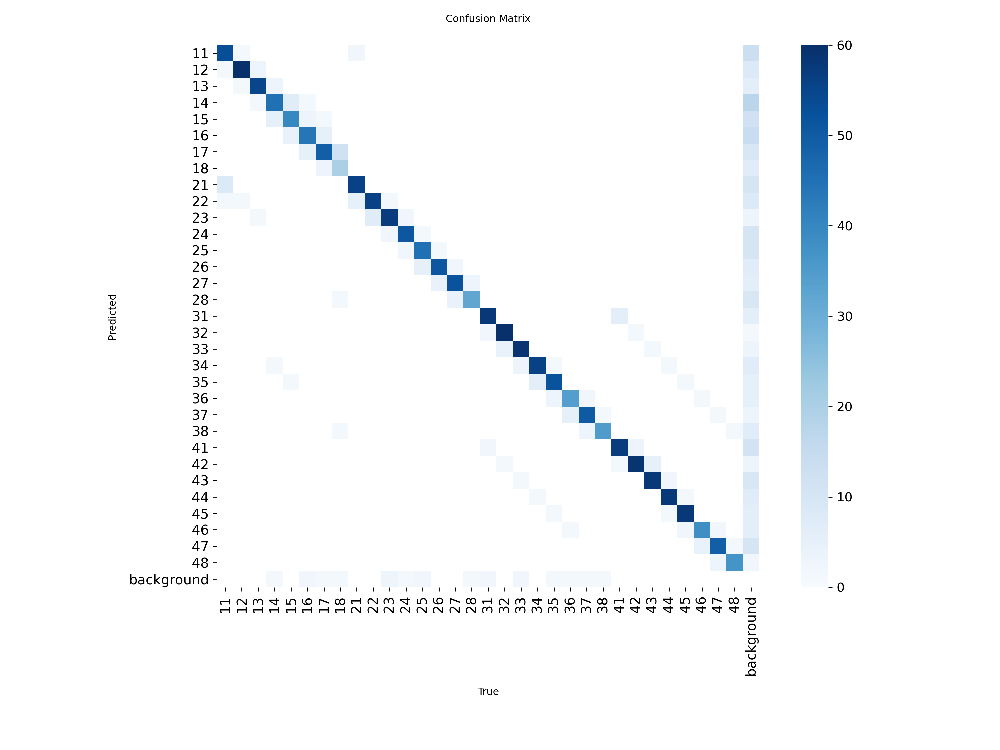

In [ ]:
# Check confusion matrix from your existing trained model
# Look specifically at whether Q3 and Q4 classes are confused with each other
from IPython.display import Image, display

conf_matrix_path = '/content/drive/MyDrive/dental_runs/opg_dentex_v1/confusion_matrix.png'
display(Image(conf_matrix_path, width=900))

In [ ]:
from ultralytics import YOLO

model = YOLO('/content/drive/MyDrive/dental_runs/opg_dentex_v2_noflip/weights/best.pt')

metrics = model.val()
print(f"--- opg_dentex_v2_noflip (rebuilt) ---")
print(f"mAP50    : {metrics.box.map50:.3f}")
print(f"mAP50-95 : {metrics.box.map:.3f}")
print(f"Precision: {metrics.box.p.mean():.3f}")
print(f"Recall   : {metrics.box.r.mean():.3f}")

Ultralytics 8.4.80 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,011,888 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3538.9±718.9 MB/s, size: 3812.6 KB)
val: Scanning /content/dentex_final/valid/labels.cache... 64 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 64/64 12.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.6s/it 6.3s
                   all         64       1791      0.877      0.878      0.918       0.52
                    11         63         63      0.967      0.937      0.976      0.534
                    12         63         63      0.947      0.857      0.946      0.519
                    13         60         60      0.913       0.87      0.945      0.488
                    14         54         55      0.772      0.764      0.851      0.433
                    15         51         52   

In [ ]:
import cv2
import numpy as np

def apply_clahe(img_path, out_path):
    img = cv2.imread(img_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8,8))
    enhanced = clahe.apply(gray)
    enhanced_bgr = cv2.cvtColor(enhanced, cv2.COLOR_GRAY2BGR)
    cv2.imwrite(out_path, enhanced_bgr)
    return out_path

def iou(b1, b2):
    x1 = max(b1[0], b2[0]); y1 = max(b1[1], b2[1])
    x2 = min(b1[2], b2[2]); y2 = min(b1[3], b2[3])
    inter = max(0, x2-x1) * max(0, y2-y1)
    area1 = (b1[2]-b1[0])*(b1[3]-b1[1])
    area2 = (b2[2]-b2[0])*(b2[3]-b2[1])
    union = area1 + area2 - inter
    return inter/union if union > 0 else 0

def dedupe_same_tooth(boxes_list, iou_thresh=0.25):
    boxes_list = sorted(boxes_list, key=lambda x: -x['confidence'])
    final = []
    for d in boxes_list:
        is_dup = any(
            f['fdi'] == d['fdi'] and iou(f['bbox'], d['bbox']) > iou_thresh
            for f in final
        )
        if not is_dup:
            final.append(d)
    return final

def run_full_pipeline(img_path, model, fdi_classes, conf=0.25, iou_nms=0.3, imgsz=1280, dedup_iou=0.25):
    """Full locked-in pipeline: CLAHE -> predict -> dedupe -> quadrant summary"""
    enhanced_path = '/content/temp_enhanced.jpg'
    apply_clahe(img_path, enhanced_path)

    res = model.predict(enhanced_path, conf=conf, iou=iou_nms, imgsz=imgsz, verbose=False)[0]

    detections = []
    for box in res.boxes:
        fdi = fdi_classes[int(box.cls)]
        detections.append({
            'fdi': fdi,
            'confidence': float(box.conf),
            'bbox': [round(v) for v in box.xyxy[0].tolist()],
        })

    clean = dedupe_same_tooth(detections, iou_thresh=dedup_iou)

    q_teeth = {'1': [], '2': [], '3': [], '4': []}
    for d in clean:
        q_teeth[d['fdi'][0]].append(d['fdi'])

    return clean, q_teeth, enhanced_path

print("Pipeline functions defined.")

Pipeline functions defined.


In [ ]:
# Use your full pipeline function with this confirmed model
clean, q_teeth, enhanced_path = run_full_pipeline(img_path, model, FDI_CLASSES)

print(f"Total detected: {len(clean)}")
for q in ['1','2','3','4']:
    names_q = {'1':'Upper Right','2':'Upper Left','3':'Lower Left','4':'Lower Right'}
    print(f"  Q{q} {names_q[q]:12s}: {len(q_teeth[q])} -> {sorted(q_teeth[q], key=int)}")

# Check for duplicates
fdi_counts = {}
for d in clean:
    fdi_counts[d['fdi']] = fdi_counts.get(d['fdi'], 0) + 1
dups = {k:v for k,v in fdi_counts.items() if v > 1}
print(f"\nDuplicates: {dups if dups else 'none'}")

Total detected: 38
  Q1 Upper Right : 12 -> ['11', '11', '12', '13', '14', '14', '15', '15', '16', '16', '17', '17']
  Q2 Upper Left  : 9 -> ['21', '23', '24', '25', '25', '26', '27', '27', '28']
  Q3 Lower Left  : 9 -> ['31', '32', '33', '33', '34', '35', '36', '37', '38']
  Q4 Lower Right : 8 -> ['41', '42', '43', '44', '44', '45', '46', '47']

Duplicates: {'25': 2, '17': 2, '11': 2, '14': 2, '16': 2, '27': 2, '15': 2, '44': 2, '33': 2}


In [ ]:
from ultralytics import YOLO

FDI_CLASSES = [
    '11','12','13','14','15','16','17','18',
    '21','22','23','24','25','26','27','28',
    '31','32','33','34','35','36','37','38',
    '41','42','43','44','45','46','47','48',
]

model = YOLO('/content/drive/MyDrive/dental_runs/opg_dentex_v2_noflip/weights/best.pt')
print("Model and FDI_CLASSES ready.")

Model and FDI_CLASSES ready.


In [ ]:
# Use your full pipeline function with this confirmed model
clean, q_teeth, enhanced_path = run_full_pipeline(img_path, model, FDI_CLASSES)

print(f"Total detected: {len(clean)}")
for q in ['1','2','3','4']:
    names_q = {'1':'Upper Right','2':'Upper Left','3':'Lower Left','4':'Lower Right'}
    print(f"  Q{q} {names_q[q]:12s}: {len(q_teeth[q])} -> {sorted(q_teeth[q], key=int)}")

# Check for duplicates
fdi_counts = {}
for d in clean:
    fdi_counts[d['fdi']] = fdi_counts.get(d['fdi'], 0) + 1
dups = {k:v for k,v in fdi_counts.items() if v > 1}
print(f"\nDuplicates: {dups if dups else 'none'}")

Total detected: 38
  Q1 Upper Right : 12 -> ['11', '11', '12', '13', '14', '14', '15', '15', '16', '16', '17', '17']
  Q2 Upper Left  : 9 -> ['21', '23', '24', '25', '25', '26', '27', '27', '28']
  Q3 Lower Left  : 9 -> ['31', '32', '33', '33', '34', '35', '36', '37', '38']
  Q4 Lower Right : 8 -> ['41', '42', '43', '44', '44', '45', '46', '47']

Duplicates: {'25': 2, '17': 2, '11': 2, '14': 2, '16': 2, '27': 2, '15': 2, '44': 2, '33': 2}


In [ ]:
from google.colab import files

print("Select your 7 test images again (Ctrl/Cmd+click to select multiple):")
uploaded = files.upload()
test_images = list(uploaded.keys())
print(f"\nUploaded {len(test_images)} images: {test_images}")

Select your 7 test images again (Ctrl/Cmd+click to select multiple):


Saving 20240807-143637138.jpg to 20240807-143637138.jpg
Saving 20231031-110753522.jpg to 20231031-110753522.jpg
Saving 20251222-130038451.jpg to 20251222-130038451.jpg
Saving 20230814-131806921.jpg to 20230814-131806921.jpg
Saving 20230821-100210854.jpg to 20230821-100210854.jpg
Saving 20250805-130531174.jpg to 20250805-130531174.jpg
Saving 20230512-143011122.jpg to 20230512-143011122.jpg

Uploaded 7 images: ['20240807-143637138.jpg', '20231031-110753522.jpg', '20251222-130038451.jpg', '20230814-131806921.jpg', '20230821-100210854.jpg', '20250805-130531174.jpg', '20230512-143011122.jpg']


In [ ]:
for img_path in test_images:
    clean, q_teeth, _ = run_full_pipeline(img_path, model, FDI_CLASSES)
    fdi_counts = {}
    for d in clean:
        fdi_counts[d['fdi']] = fdi_counts.get(d['fdi'], 0) + 1
    dups = {k:v for k,v in fdi_counts.items() if v > 1}
    print(f"{img_path}: {len(clean)} teeth  duplicates={dups if dups else 'none'}")

20240807-143637138.jpg: 29 teeth  duplicates={'11': 2, '25': 2, '27': 2}
20231031-110753522.jpg: 34 teeth  duplicates={'46': 2, '13': 2, '12': 2, '31': 2, '16': 2, '11': 2}
20251222-130038451.jpg: 35 teeth  duplicates={'46': 2, '16': 2, '47': 2, '37': 3, '17': 2, '14': 2, '44': 2}
20230814-131806921.jpg: 27 teeth  duplicates={'47': 2, '17': 2, '21': 2}
20230821-100210854.jpg: 32 teeth  duplicates={'12': 2, '25': 2, '41': 2, '13': 2}
20250805-130531174.jpg: 31 teeth  duplicates={'26': 2, '47': 2, '25': 2, '46': 2, '27': 2, '16': 2, '15': 2}
20230512-143011122.jpg: 22 teeth  duplicates={'46': 2, '27': 2, '37': 2}


In [ ]:
# Debug: print the raw FDI string and what quadrant digit gets extracted
for box in res2.boxes:
    cls_id = int(box.cls)
    fdi = FDI_CLASSES[cls_id]
    quadrant_digit = fdi[0]
    print(f"cls_id={cls_id}  fdi='{fdi}' (type={type(fdi)})  quadrant_digit='{quadrant_digit}'")

cls_id=12  fdi='25' (type=<class 'str'>)  quadrant_digit='2'
cls_id=6  fdi='17' (type=<class 'str'>)  quadrant_digit='1'
cls_id=0  fdi='11' (type=<class 'str'>)  quadrant_digit='1'
cls_id=3  fdi='14' (type=<class 'str'>)  quadrant_digit='1'
cls_id=29  fdi='46' (type=<class 'str'>)  quadrant_digit='4'
cls_id=23  fdi='38' (type=<class 'str'>)  quadrant_digit='3'
cls_id=13  fdi='26' (type=<class 'str'>)  quadrant_digit='2'
cls_id=22  fdi='37' (type=<class 'str'>)  quadrant_digit='3'
cls_id=2  fdi='13' (type=<class 'str'>)  quadrant_digit='1'
cls_id=5  fdi='16' (type=<class 'str'>)  quadrant_digit='1'
cls_id=11  fdi='24' (type=<class 'str'>)  quadrant_digit='2'
cls_id=14  fdi='27' (type=<class 'str'>)  quadrant_digit='2'
cls_id=29  fdi='46' (type=<class 'str'>)  quadrant_digit='4'
cls_id=17  fdi='32' (type=<class 'str'>)  quadrant_digit='3'
cls_id=4  fdi='15' (type=<class 'str'>)  quadrant_digit='1'
cls_id=25  fdi='42' (type=<class 'str'>)  quadrant_digit='4'
cls_id=28  fdi='45' (type=<cla

In [ ]:
# Always reset before counting — paste this fresh, don't reuse old dict from a previous cell
q_teeth = {'1': [], '2': [], '3': [], '4': []}

for box in res2.boxes:
    cls_id = int(box.cls)
    fdi = FDI_CLASSES[cls_id]
    q_teeth[fdi[0]].append(fdi)

for q in ['1','2','3','4']:
    print(f"Q{q}: {len(q_teeth[q])} -> {sorted(q_teeth[q], key=int)}")

Q1: 12 -> ['11', '11', '12', '13', '14', '14', '15', '15', '16', '16', '17', '17']
Q2: 10 -> ['21', '23', '24', '25', '25', '25', '26', '27', '27', '28']
Q3: 10 -> ['31', '32', '33', '33', '34', '35', '36', '37', '37', '38']
Q4: 10 -> ['41', '42', '42', '43', '44', '44', '45', '46', '46', '47']


In [ ]:
# Print every single Q3 detection with its FDI number and confidence
print("All Q3 (Lower Left) detections:")
for box in res2.boxes:
    fdi = FDI_CLASSES[int(box.cls)]
    if fdi[0] == '3':
        conf = float(box.conf)
        bbox = [round(v) for v in box.xyxy[0].tolist()]
        print(f"  {fdi}  conf={conf:.2f}  bbox={bbox}")

All Q3 (Lower Left) detections:
  38  conf=0.76  bbox=[3061, 1062, 3265, 1346]
  37  conf=0.74  bbox=[2856, 1055, 3215, 1429]
  32  conf=0.60  bbox=[2093, 1156, 2227, 1525]
  36  conf=0.57  bbox=[2709, 1110, 3054, 1506]
  34  conf=0.49  bbox=[2281, 1180, 2432, 1570]
  33  conf=0.45  bbox=[2176, 1149, 2328, 1542]
  37  conf=0.44  bbox=[2719, 1107, 3018, 1501]
  35  conf=0.37  bbox=[2388, 1169, 2601, 1587]
  31  conf=0.31  bbox=[2012, 1169, 2153, 1459]
  33  conf=0.27  bbox=[2278, 1175, 2436, 1589]


In [ ]:
res2 = model.predict(
    '/content/enhanced_test.jpg',
    conf  = 0.25,
    iou   = 0.3,      # LOWERED from 0.5 — merges these near-duplicate boxes
    imgsz = 1280,
    verbose = False,
)[0]

print(f"Detected {len(res2.boxes)} teeth")

# Re-run the quadrant check
q_teeth = {'1': [], '2': [], '3': [], '4': []}
for box in res2.boxes:
    fdi = FDI_CLASSES[int(box.cls)]
    q_teeth[fdi[0]].append(fdi)

for q in ['1','2','3','4']:
    print(f"Q{q}: {len(q_teeth[q])} -> {sorted(q_teeth[q], key=int)}")

Detected 41 teeth
Q1: 12 -> ['11', '11', '12', '13', '14', '14', '15', '15', '16', '16', '17', '17']
Q2: 10 -> ['21', '23', '24', '25', '25', '25', '26', '27', '27', '28']
Q3: 10 -> ['31', '32', '33', '33', '34', '35', '36', '37', '37', '38']
Q4: 9 -> ['41', '42', '43', '44', '44', '45', '46', '46', '47']


In [ ]:
def dedupe_same_tooth(boxes_list, iou_thresh=0.4):
    """
    Final safety net: for any two boxes with the SAME fdi number
    that overlap more than iou_thresh, keep only the higher confidence one.
    """
    def iou(b1, b2):
        x1 = max(b1[0], b2[0]); y1 = max(b1[1], b2[1])
        x2 = min(b1[2], b2[2]); y2 = min(b1[3], b2[3])
        inter = max(0, x2-x1) * max(0, y2-y1)
        area1 = (b1[2]-b1[0])*(b1[3]-b1[1])
        area2 = (b2[2]-b2[0])*(b2[3]-b2[1])
        union = area1 + area2 - inter
        return inter/union if union > 0 else 0

    boxes_list.sort(key=lambda x: -x['confidence'])
    final = []
    for d in boxes_list:
        is_dup = any(
            f['fdi'] == d['fdi'] and iou(f['bbox'], d['bbox']) > iou_thresh
            for f in final
        )
        if not is_dup:
            final.append(d)
    return final


# Build detection list from res2, then dedupe
detections = []
for box in res2.boxes:
    fdi = FDI_CLASSES[int(box.cls)]
    detections.append({
        'fdi': fdi,
        'confidence': float(box.conf),
        'bbox': [round(v) for v in box.xyxy[0].tolist()],
    })

clean_detections = dedupe_same_tooth(detections, iou_thresh=0.4)

print(f"Before dedup: {len(detections)}")
print(f"After dedup : {len(clean_detections)}")

q_teeth = {'1': [], '2': [], '3': [], '4': []}
for d in clean_detections:
    q_teeth[d['fdi'][0]].append(d['fdi'])

for q in ['1','2','3','4']:
    print(f"Q{q}: {len(q_teeth[q])} -> {sorted(q_teeth[q], key=int)}")

Before dedup: 41
After dedup : 41
Q1: 12 -> ['11', '11', '12', '13', '14', '14', '15', '15', '16', '16', '17', '17']
Q2: 10 -> ['21', '23', '24', '25', '25', '25', '26', '27', '27', '28']
Q3: 10 -> ['31', '32', '33', '33', '34', '35', '36', '37', '37', '38']
Q4: 9 -> ['41', '42', '43', '44', '44', '45', '46', '46', '47']


In [ ]:
clean_detections = dedupe_same_tooth(detections, iou_thresh=0.25)  # lowered from 0.4

q_teeth = {'1': [], '2': [], '3': [], '4': []}
for d in clean_detections:
    q_teeth[d['fdi'][0]].append(d['fdi'])

for q in ['1','2','3','4']:
    print(f"Q{q}: {len(q_teeth[q])} -> {sorted(q_teeth[q], key=int)}")

Q1: 12 -> ['11', '11', '12', '13', '14', '14', '15', '15', '16', '16', '17', '17']
Q2: 9 -> ['21', '23', '24', '25', '25', '26', '27', '27', '28']
Q3: 9 -> ['31', '32', '33', '33', '34', '35', '36', '37', '38']
Q4: 8 -> ['41', '42', '43', '44', '44', '45', '46', '47']


In [ ]:
print("Both '15' detections:")
for d in detections:
    if d['fdi'] == '15':
        print(f"  conf={d['confidence']:.2f}  bbox={d['bbox']}")

print("\nBoth '44' detections:")
for d in detections:
    if d['fdi'] == '44':
        print(f"  conf={d['confidence']:.2f}  bbox={d['bbox']}")

Both '15' detections:
  conf=0.58  bbox=[1404, 646, 1607, 1076]
  conf=0.39  bbox=[1529, 644, 1722, 1093]

Both '44' detections:
  conf=0.47  bbox=[1434, 1115, 1713, 1571]
  conf=0.25  bbox=[1723, 1157, 1867, 1548]


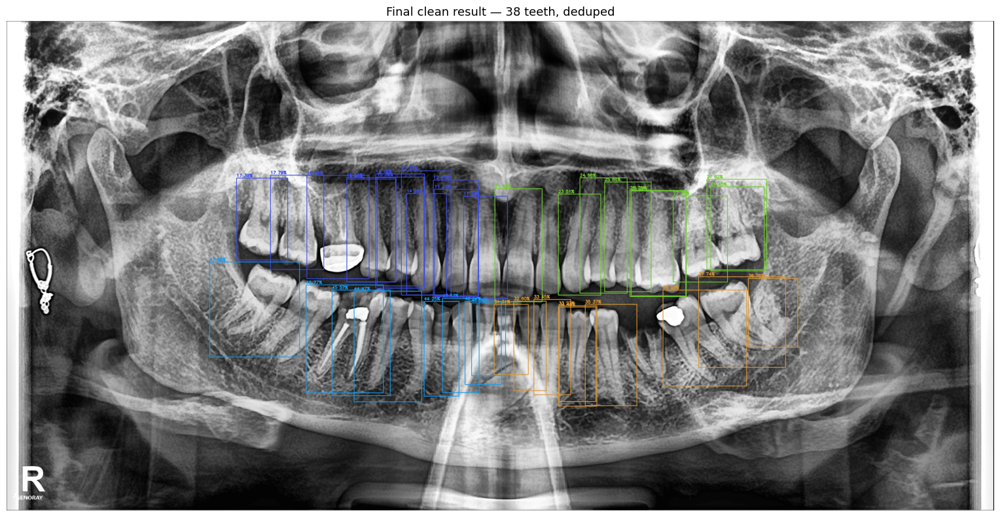

In [ ]:
import cv2
import matplotlib.pyplot as plt

orig = cv2.imread('/content/enhanced_test.jpg')
quadrant_colors = {
    '1': (231, 76, 60), '2': (46, 204, 113),
    '3': (52, 152, 219), '4': (243, 156, 18),
}

result = orig.copy()
for d in clean_detections:
    x1, y1, x2, y2 = d['bbox']
    fdi = d['fdi']
    color = quadrant_colors[fdi[0]]
    cv2.rectangle(result, (x1,y1), (x2,y2), color, 2)
    label = f"{fdi} {d['confidence']:.0%}"
    cv2.putText(result, label, (x1, max(15,y1-5)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.55, color, 2)

plt.figure(figsize=(18, 8))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title(f"Final clean result — {len(clean_detections)} teeth, deduped", fontsize=13)
plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

def apply_clahe(img_path, out_path):
    img = cv2.imread(img_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8,8))
    enhanced = clahe.apply(gray)
    enhanced_bgr = cv2.cvtColor(enhanced, cv2.COLOR_GRAY2BGR)
    cv2.imwrite(out_path, enhanced_bgr)
    return out_path

def iou(b1, b2):
    x1 = max(b1[0], b2[0]); y1 = max(b1[1], b2[1])
    x2 = min(b1[2], b2[2]); y2 = min(b1[3], b2[3])
    inter = max(0, x2-x1) * max(0, y2-y1)
    area1 = (b1[2]-b1[0])*(b1[3]-b1[1])
    area2 = (b2[2]-b2[0])*(b2[3]-b2[1])
    union = area1 + area2 - inter
    return inter/union if union > 0 else 0

def dedupe_same_tooth(boxes_list, iou_thresh=0.25):
    boxes_list = sorted(boxes_list, key=lambda x: -x['confidence'])
    final = []
    for d in boxes_list:
        is_dup = any(
            f['fdi'] == d['fdi'] and iou(f['bbox'], d['bbox']) > iou_thresh
            for f in final
        )
        if not is_dup:
            final.append(d)
    return final

def run_full_pipeline(img_path, model, fdi_classes, conf=0.25, iou_nms=0.3, imgsz=1280, dedup_iou=0.25):
    """Your full locked-in pipeline: CLAHE -> predict -> dedupe -> quadrant summary"""
    enhanced_path = '/content/temp_enhanced.jpg'
    apply_clahe(img_path, enhanced_path)

    res = model.predict(enhanced_path, conf=conf, iou=iou_nms, imgsz=imgsz, verbose=False)[0]

    detections = []
    for box in res.boxes:
        fdi = fdi_classes[int(box.cls)]
        detections.append({
            'fdi': fdi,
            'confidence': float(box.conf),
            'bbox': [round(v) for v in box.xyxy[0].tolist()],
        })

    clean = dedupe_same_tooth(detections, iou_thresh=dedup_iou)

    q_teeth = {'1': [], '2': [], '3': [], '4': []}
    for d in clean:
        q_teeth[d['fdi'][0]].append(d['fdi'])

    return clean, q_teeth, enhanced_path

In [ ]:
# ── Upload multiple raw OPG images at once ──
print("Select multiple images (Ctrl/Cmd+click to select several):")
uploaded = files.upload()
test_images = list(uploaded.keys())
print(f"\nUploaded {len(test_images)} images: {test_images}")

Select multiple images (Ctrl/Cmd+click to select several):


Saving 20240807-143637138.jpg to 20240807-143637138 (1).jpg
Saving 20231031-110753522.jpg to 20231031-110753522 (1).jpg
Saving 20251222-130038451.jpg to 20251222-130038451 (1).jpg
Saving 20230814-131806921.jpg to 20230814-131806921 (1).jpg
Saving 20230821-100210854.jpg to 20230821-100210854 (1).jpg
Saving 20250805-130531174.jpg to 20250805-130531174 (1).jpg
Saving 20230512-143011122.jpg to 20230512-143011122 (1).jpg

Uploaded 7 images: ['20240807-143637138 (1).jpg', '20231031-110753522 (1).jpg', '20251222-130038451 (1).jpg', '20230814-131806921 (1).jpg', '20230821-100210854 (1).jpg', '20250805-130531174 (1).jpg', '20230512-143011122 (1).jpg']


In [ ]:
# ── Run pipeline on all of them and compare ──
all_results = {}

for img_path in test_images:
    clean, q_teeth, enhanced_path = run_full_pipeline(img_path, model, FDI_CLASSES)
    total = len(clean)
    all_results[img_path] = (clean, q_teeth, enhanced_path)

    print(f"\n{'='*60}")
    print(f"Image: {img_path}")
    print(f"Total detected: {total}")
    for q in ['1','2','3','4']:
        print(f"  Q{q}: {len(q_teeth[q])} -> {sorted(q_teeth[q], key=int)}")

    # Flag suspicious results
    if total > 32:
        print(f"  WARNING: {total} exceeds biological max of 32")
    if any(len(q_teeth[q]) > 8 for q in ['1','2','3','4']):
        print(f"  WARNING: a quadrant exceeds max of 8 teeth")


Image: 20240807-143637138 (1).jpg
Total detected: 29
  Q1: 8 -> ['11', '11', '12', '13', '14', '15', '16', '17']
  Q2: 9 -> ['21', '23', '24', '25', '25', '26', '27', '27', '28']
  Q3: 5 -> ['31', '32', '33', '34', '35']
  Q4: 7 -> ['41', '42', '43', '44', '45', '46', '47']

Image: 20231031-110753522 (1).jpg
Total detected: 34
  Q1: 11 -> ['11', '11', '12', '12', '13', '13', '14', '15', '16', '16', '17']
  Q2: 6 -> ['21', '23', '24', '25', '26', '27']
  Q3: 9 -> ['31', '31', '32', '33', '34', '35', '36', '37', '38']
  Q4: 8 -> ['41', '42', '43', '44', '45', '46', '46', '47']

Image: 20251222-130038451 (1).jpg
Total detected: 35
  Q1: 9 -> ['11', '13', '14', '14', '15', '16', '16', '17', '17']
  Q2: 7 -> ['21', '22', '24', '25', '26', '27', '28']
  Q3: 9 -> ['31', '32', '33', '34', '36', '37', '37', '37', '38']
  Q4: 10 -> ['41', '42', '43', '44', '44', '45', '46', '46', '47', '47']

Image: 20230814-131806921 (1).jpg
Total detected: 27
  Q1: 7 -> ['11', '13', '14', '15', '16', '17', '1

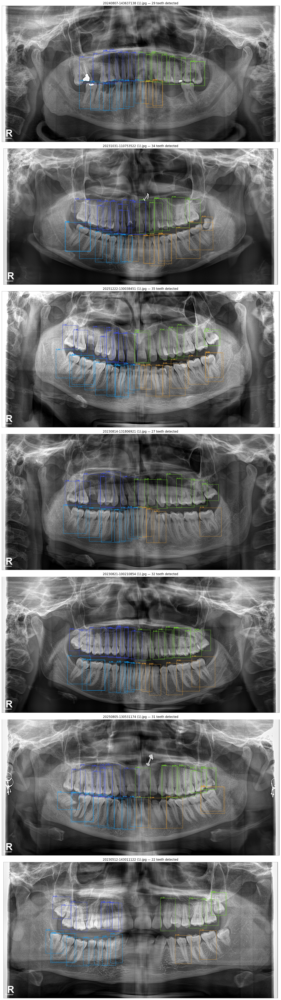

In [ ]:
# ── Visualize all results side by side ──
quadrant_colors = {
    '1': (231, 76, 60), '2': (46, 204, 113),
    '3': (52, 152, 219), '4': (243, 156, 18),
}

n = len(test_images)
fig, axes = plt.subplots(n, 1, figsize=(18, 8*n))
if n == 1:
    axes = [axes]

for ax, img_path in zip(axes, test_images):
    clean, q_teeth, enhanced_path = all_results[img_path]
    orig = cv2.imread(img_path)
    result = orig.copy()

    for d in clean:
        x1, y1, x2, y2 = d['bbox']
        color = quadrant_colors[d['fdi'][0]]
        cv2.rectangle(result, (x1,y1), (x2,y2), color, 2)
        cv2.putText(result, f"{d['fdi']} {d['confidence']:.0%}",
                    (x1, max(15,y1-5)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)

    ax.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{img_path} — {len(clean)} teeth detected", fontsize=12)
    ax.axis('off')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/dental_runs/batch_test_results.jpg', dpi=100)
plt.show()

In [ ]:
# ═══════════════════════════════════════════════════════════
# DENTAL OPG — COMPLETE SESSION SETUP
# Run this ONE cell first, every session. Everything else
# (model, FDI classes, CLAHE, dedup, pipeline) gets defined here.
# ═══════════════════════════════════════════════════════════

# ── 1. Install + mount Drive ──
get_ipython().system('pip install ultralytics -q')

from google.colab import drive
drive.mount('/content/drive')

import os, glob, cv2, torch, numpy as np
from datetime import datetime
from ultralytics import YOLO

print(f"GPU  : {torch.cuda.get_device_name(0)}")
print(f"VRAM : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")

# ── 2. FDI class list (fixed, never changes) ──
FDI_CLASSES = [
    '11','12','13','14','15','16','17','18',
    '21','22','23','24','25','26','27','28',
    '31','32','33','34','35','36','37','38',
    '41','42','43','44','45','46','47','48',
]

# ── 3. Locate and load the validated model ──
# Update this path if your validated model lives somewhere else
VALIDATED_MODEL = '/content/drive/MyDrive/dental_runs/opg_dentex_v2_noflip/weights/best.pt'

if not os.path.exists(VALIDATED_MODEL):
    print(f"WARNING: model not found at {VALIDATED_MODEL}")
    print("Searching for available models...")
    runs = glob.glob('/content/drive/MyDrive/dental_runs/*/weights/best.pt')
    for r in sorted(runs):
        size_mb = os.path.getsize(r) / 1e6
        mtime = datetime.fromtimestamp(os.path.getmtime(r)).strftime('%Y-%m-%d %H:%M')
        print(f"  {r}  ({size_mb:.1f} MB, modified {mtime})")
    print("\nUpdate VALIDATED_MODEL above with the correct path, then re-run this cell.")
else:
    model = YOLO(VALIDATED_MODEL)
    print(f"\nModel loaded: {VALIDATED_MODEL}")

# ── 4. CLAHE preprocessing ──
def apply_clahe(img_path, out_path):
    img = cv2.imread(img_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray)
    enhanced_bgr = cv2.cvtColor(enhanced, cv2.COLOR_GRAY2BGR)
    cv2.imwrite(out_path, enhanced_bgr)
    return out_path

# ── 5. IOU + same-tooth dedup ──
def iou(b1, b2):
    x1 = max(b1[0], b2[0]); y1 = max(b1[1], b2[1])
    x2 = min(b1[2], b2[2]); y2 = min(b1[3], b2[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    area1 = (b1[2] - b1[0]) * (b1[3] - b1[1])
    area2 = (b2[2] - b2[0]) * (b2[3] - b2[1])
    union = area1 + area2 - inter
    return inter / union if union > 0 else 0

def dedupe_same_tooth(boxes_list, iou_thresh=0.25):
    boxes_list = sorted(boxes_list, key=lambda x: -x['confidence'])
    final = []
    for d in boxes_list:
        is_dup = any(
            f['fdi'] == d['fdi'] and iou(f['bbox'], d['bbox']) > iou_thresh
            for f in final
        )
        if not is_dup:
            final.append(d)
    return final

# ── 6. Full prediction pipeline ──
def run_full_pipeline(img_path, model, fdi_classes,
                      conf=0.25, iou_nms=0.3, imgsz=1280, dedup_iou=0.25):
    """
    Locked-in pipeline: CLAHE -> predict -> dedupe -> quadrant summary
    Returns: (clean_detections, quadrant_dict, enhanced_image_path)
    """
    enhanced_path = '/content/temp_enhanced.jpg'
    apply_clahe(img_path, enhanced_path)

    res = model.predict(enhanced_path, conf=conf, iou=iou_nms,
                        imgsz=imgsz, verbose=False)[0]

    detections = []
    for box in res.boxes:
        fdi = fdi_classes[int(box.cls)]
        detections.append({
            'fdi': fdi,
            'confidence': float(box.conf),
            'bbox': [round(v) for v in box.xyxy[0].tolist()],
        })

    clean = dedupe_same_tooth(detections, iou_thresh=dedup_iou)

    q_teeth = {'1': [], '2': [], '3': [], '4': []}
    for d in clean:
        q_teeth[d['fdi'][0]].append(d['fdi'])

    return clean, q_teeth, enhanced_path

# ── 7. Visualization helper ──
def visualize_result(img_path, clean_detections, title=None, save_path=None):
    import matplotlib.pyplot as plt

    quadrant_colors = {
        '1': (231, 76, 60), '2': (46, 204, 113),
        '3': (52, 152, 219), '4': (243, 156, 18),
    }

    orig = cv2.imread(img_path)
    result = orig.copy()

    for d in clean_detections:
        x1, y1, x2, y2 = d['bbox']
        color = quadrant_colors[d['fdi'][0]]
        cv2.rectangle(result, (x1, y1), (x2, y2), color, 2)
        label = f"{d['fdi']} {d['confidence']:.0%}"
        cv2.putText(result, label, (x1, max(15, y1 - 5)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, color, 2)

    plt.figure(figsize=(18, 8))
    plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    plt.title(title or f"Detected {len(clean_detections)} teeth", fontsize=13)
    plt.axis('off')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=100)
    plt.show()

# ── 8. Quick summary printer ──
def print_summary(img_path, clean_detections, q_teeth):
    names_q = {'1':'Upper Right','2':'Upper Left','3':'Lower Left','4':'Lower Right'}

    fdi_counts = {}
    for d in clean_detections:
        fdi_counts[d['fdi']] = fdi_counts.get(d['fdi'], 0) + 1
    dups = {k: v for k, v in fdi_counts.items() if v > 1}

    print(f"\n{img_path}")
    print(f"  Total detected: {len(clean_detections)}")
    for q in ['1', '2', '3', '4']:
        missing = [t for t in FDI_CLASSES if t[0] == q and t not in q_teeth[q]]
        print(f"  Q{q} {names_q[q]:12s}: {len(q_teeth[q])} -> {sorted(q_teeth[q], key=int)}  missing={missing}")
    print(f"  Duplicates: {dups if dups else 'none'}")

print("\n" + "="*60)
print("SETUP COMPLETE")
print("="*60)
print("Available now: model, FDI_CLASSES, run_full_pipeline(),")
print("visualize_result(), print_summary(), dedupe_same_tooth()")
print("\nNext step: upload test images with:")
print("  from google.colab import files")
print("  uploaded = files.upload()")
print("  test_images = list(uploaded.keys())")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
GPU  : Tesla T4
VRAM : 15.6 GB

Model loaded: /content/drive/MyDrive/dental_runs/opg_dentex_v2_noflip/weights/best.pt

SETUP COMPLETE
Available now: model, FDI_CLASSES, run_full_pipeline(),
visualize_result(), print_summary(), dedupe_same_tooth()

Next step: upload test images with:
  from google.colab import files
  uploaded = files.upload()
  test_images = list(uploaded.keys())


In [ ]:
from google.colab import files
uploaded = files.upload()
test_images = list(uploaded.keys())

In [ ]:
for img_path in test_images:
    clean, q_teeth, _ = run_full_pipeline(img_path, model, FDI_CLASSES)
    print_summary(img_path, clean, q_teeth)


20240807-143637138 (1).jpg
  Total detected: 29
  Q1 Upper Right : 8 -> ['11', '11', '12', '13', '14', '15', '16', '17']  missing=['18']
  Q2 Upper Left  : 9 -> ['21', '23', '24', '25', '25', '26', '27', '27', '28']  missing=['22']
  Q3 Lower Left  : 5 -> ['31', '32', '33', '34', '35']  missing=['36', '37', '38']
  Q4 Lower Right : 7 -> ['41', '42', '43', '44', '45', '46', '47']  missing=['48']
  Duplicates: {'11': 2, '25': 2, '27': 2}

20231031-110753522 (1).jpg
  Total detected: 34
  Q1 Upper Right : 11 -> ['11', '11', '12', '12', '13', '13', '14', '15', '16', '16', '17']  missing=['18']
  Q2 Upper Left  : 6 -> ['21', '23', '24', '25', '26', '27']  missing=['22', '28']
  Q3 Lower Left  : 9 -> ['31', '31', '32', '33', '34', '35', '36', '37', '38']  missing=[]
  Q4 Lower Right : 8 -> ['41', '42', '43', '44', '45', '46', '46', '47']  missing=['48']
  Duplicates: {'46': 2, '13': 2, '12': 2, '31': 2, '16': 2, '11': 2}

20251222-130038451 (1).jpg
  Total detected: 35
  Q1 Upper Right : 9 

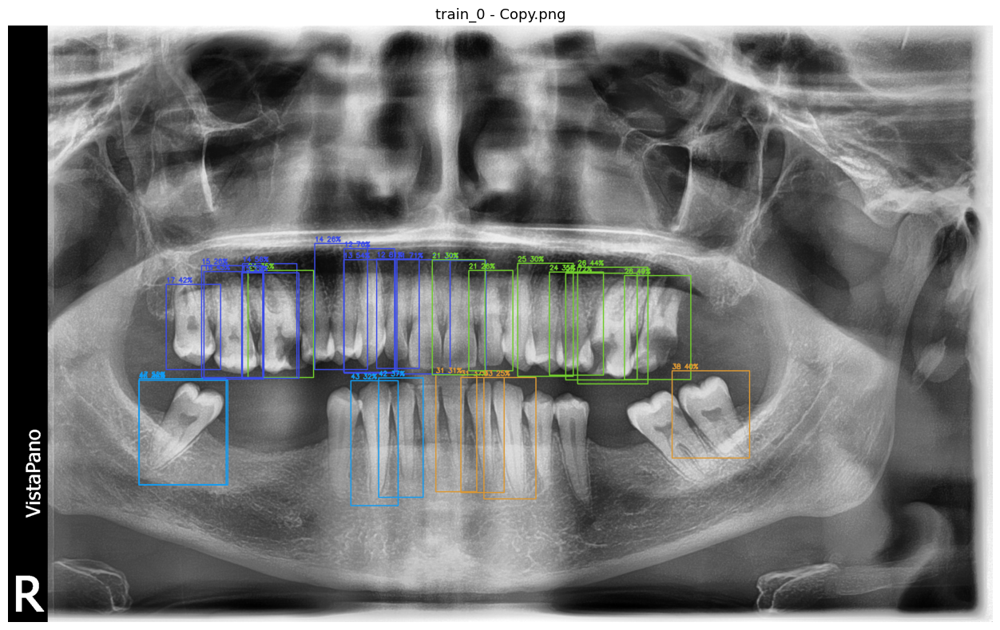

In [ ]:
# Visualize any one of them
visualize_result(test_images[0], *run_full_pipeline(test_images[0], model, FDI_CLASSES)[:2][0:1],
                 title=test_images[0])

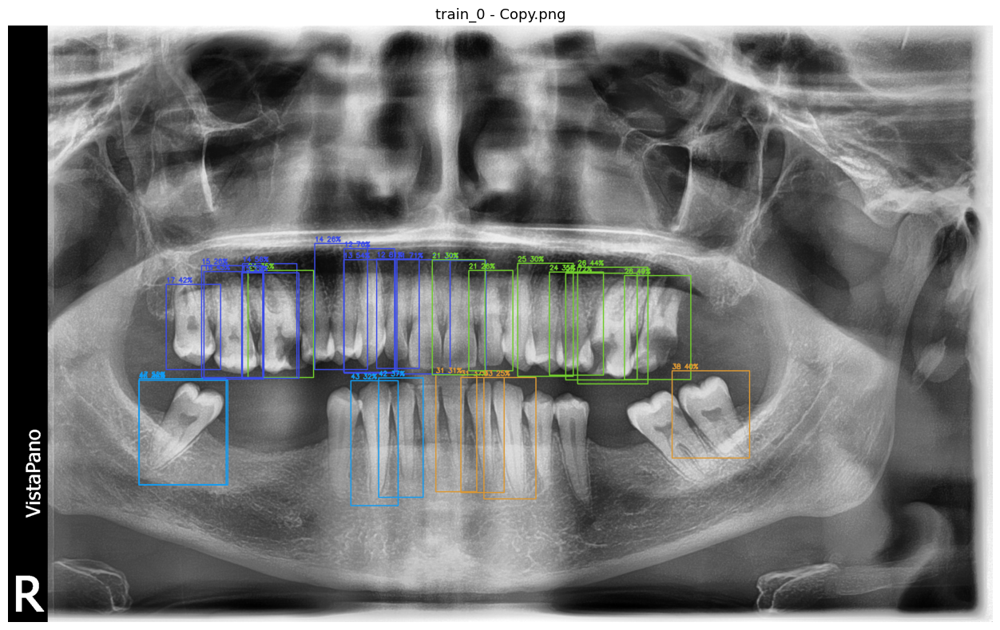

In [ ]:
clean, q_teeth, enhanced = run_full_pipeline(test_images[0], model, FDI_CLASSES)
visualize_result(test_images[0], clean, title=test_images[0])

In [ ]:
def enforce_unique_fdi(detections):
    """
    Hard biological constraint: each FDI number can appear at most once
    per image. If the same FDI shows up multiple times (even in totally
    different locations), keep only the highest-confidence one.

    This catches label errors that spatial IOU dedup misses --
    e.g. the model predicting '11' on two different, non-overlapping teeth.
    """
    best_per_fdi = {}
    removed = []

    for d in sorted(detections, key=lambda x: -x['confidence']):
        fdi = d['fdi']
        if fdi not in best_per_fdi:
            best_per_fdi[fdi] = d
        else:
            removed.append(d)   # track what got discarded, for transparency

    final = sorted(best_per_fdi.values(), key=lambda x: int(x['fdi']))
    return final, removed

In [ ]:
def run_full_pipeline(img_path, model, fdi_classes,
                      conf=0.25, iou_nms=0.3, imgsz=1280, dedup_iou=0.25):
    enhanced_path = '/content/temp_enhanced.jpg'
    apply_clahe(img_path, enhanced_path)

    res = model.predict(enhanced_path, conf=conf, iou=iou_nms,
                        imgsz=imgsz, verbose=False)[0]

    detections = []
    for box in res.boxes:
        fdi = fdi_classes[int(box.cls)]
        detections.append({
            'fdi': fdi,
            'confidence': float(box.conf),
            'bbox': [round(v) for v in box.xyxy[0].tolist()],
        })

    # Step 1: remove spatial duplicates (same tooth, overlapping boxes)
    spatial_clean = dedupe_same_tooth(detections, iou_thresh=dedup_iou)

    # Step 2: enforce biological constraint (no FDI number twice, anywhere)
    final_clean, removed = enforce_unique_fdi(spatial_clean)

    q_teeth = {'1': [], '2': [], '3': [], '4': []}
    for d in final_clean:
        q_teeth[d['fdi'][0]].append(d['fdi'])

    return final_clean, q_teeth, enhanced_path, removed

In [ ]:
def print_summary(img_path, clean_detections, q_teeth, removed=None):
    names_q = {'1':'Upper Right','2':'Upper Left','3':'Lower Left','4':'Lower Right'}

    print(f"\n{img_path}")
    print(f"  Total unique teeth: {len(clean_detections)}")

    for q in ['1', '2', '3', '4']:
        # q_teeth[q] is now guaranteed unique, so sorted() is clean
        present = sorted(set(q_teeth[q]), key=int)
        missing = [t for t in FDI_CLASSES if t[0] == q and t not in present]
        print(f"  Q{q} {names_q[q]:12s}: {len(present)} -> {present}  missing={missing}")

    if removed:
        print(f"  Flagged (same FDI predicted twice, lower-confidence copy dropped):")
        for d in removed:
            print(f"    {d['fdi']}  conf={d['confidence']:.2f}  bbox={d['bbox']}")
    else:
        print(f"  No duplicate FDI labels found.")

In [ ]:
for img_path in test_images:
    clean, q_teeth, _, removed = run_full_pipeline(img_path, model, FDI_CLASSES)
    print_summary(img_path, clean, q_teeth, removed)


20240807-143637138 (1).jpg
  Total unique teeth: 26
  Q1 Upper Right : 7 -> ['11', '12', '13', '14', '15', '16', '17']  missing=['18']
  Q2 Upper Left  : 7 -> ['21', '23', '24', '25', '26', '27', '28']  missing=['22']
  Q3 Lower Left  : 5 -> ['31', '32', '33', '34', '35']  missing=['36', '37', '38']
  Q4 Lower Right : 7 -> ['41', '42', '43', '44', '45', '46', '47']  missing=['48']
  Flagged (same FDI predicted twice, lower-confidence copy dropped):
    27  conf=0.41  bbox=[2804, 828, 3017, 1187]
    25  conf=0.40  bbox=[2375, 735, 2567, 1163]
    11  conf=0.29  bbox=[1932, 702, 2109, 1118]

20231031-110753522 (1).jpg
  Total unique teeth: 28
  Q1 Upper Right : 7 -> ['11', '12', '13', '14', '15', '16', '17']  missing=['18']
  Q2 Upper Left  : 6 -> ['21', '23', '24', '25', '26', '27']  missing=['22', '28']
  Q3 Lower Left  : 8 -> ['31', '32', '33', '34', '35', '36', '37', '38']  missing=[]
  Q4 Lower Right : 7 -> ['41', '42', '43', '44', '45', '46', '47']  missing=['48']
  Flagged (same

In [ ]:
for img_path in test_images:
    clean, q_teeth, _, removed = run_full_pipeline(img_path, model, FDI_CLASSES)
    print_summary(img_path, clean, q_teeth, removed)


20240807-143637138 (1).jpg
  Total unique teeth: 26
  Q1 Upper Right : 7 -> ['11', '12', '13', '14', '15', '16', '17']  missing=['18']
  Q2 Upper Left  : 7 -> ['21', '23', '24', '25', '26', '27', '28']  missing=['22']
  Q3 Lower Left  : 5 -> ['31', '32', '33', '34', '35']  missing=['36', '37', '38']
  Q4 Lower Right : 7 -> ['41', '42', '43', '44', '45', '46', '47']  missing=['48']
  Flagged (same FDI predicted twice, lower-confidence copy dropped):
    27  conf=0.41  bbox=[2804, 828, 3017, 1187]
    25  conf=0.40  bbox=[2375, 735, 2567, 1163]
    11  conf=0.29  bbox=[1932, 702, 2109, 1118]

20231031-110753522 (1).jpg
  Total unique teeth: 28
  Q1 Upper Right : 7 -> ['11', '12', '13', '14', '15', '16', '17']  missing=['18']
  Q2 Upper Left  : 6 -> ['21', '23', '24', '25', '26', '27']  missing=['22', '28']
  Q3 Lower Left  : 8 -> ['31', '32', '33', '34', '35', '36', '37', '38']  missing=[]
  Q4 Lower Right : 7 -> ['41', '42', '43', '44', '45', '46', '47']  missing=['48']
  Flagged (same

In [ ]:
# Count how often each FDI number appears in the "flagged/removed" list
# across ALL your test images — this tells you which teeth the model
# genuinely struggles with
from collections import Counter

all_removed_fdis = []
for img_path in test_images:
    clean, q_teeth, _, removed = run_full_pipeline(img_path, model, FDI_CLASSES)
    all_removed_fdis.extend([d['fdi'] for d in removed])

print("Most frequently double-predicted teeth:")
for fdi, count in Counter(all_removed_fdis).most_common(10):
    print(f"  Tooth {fdi}: flagged {count} times")

Most frequently double-predicted teeth:
  Tooth 25: flagged 3 times
  Tooth 46: flagged 3 times
  Tooth 16: flagged 3 times
  Tooth 47: flagged 3 times
  Tooth 27: flagged 2 times
  Tooth 11: flagged 2 times
  Tooth 13: flagged 2 times
  Tooth 12: flagged 2 times
  Tooth 17: flagged 2 times
  Tooth 37: flagged 2 times


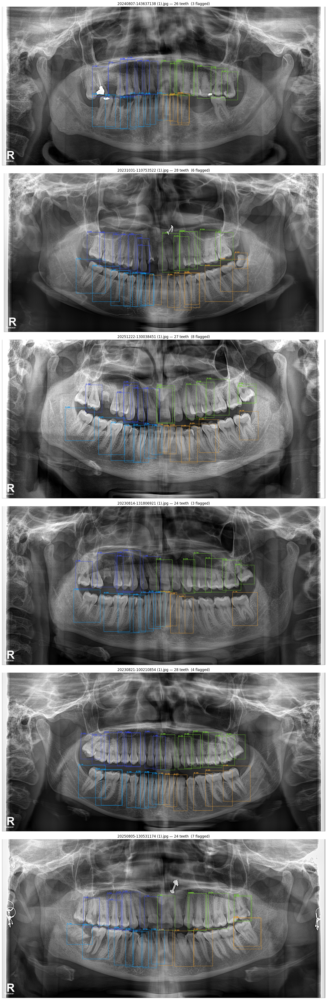

In [ ]:
import cv2
import matplotlib.pyplot as plt

quadrant_colors = {
    '1': (231, 76, 60), '2': (46, 204, 113),
    '3': (52, 152, 219), '4': (243, 156, 18),
}

n = len(test_images)
fig, axes = plt.subplots(n, 1, figsize=(18, 8*n))
if n == 1:
    axes = [axes]

for ax, img_path in zip(axes, test_images):
    clean, q_teeth, enhanced_path, removed = run_full_pipeline(img_path, model, FDI_CLASSES)

    orig = cv2.imread(img_path)
    result = orig.copy()

    for d in clean:
        x1, y1, x2, y2 = d['bbox']
        color = quadrant_colors[d['fdi'][0]]
        cv2.rectangle(result, (x1, y1), (x2, y2), color, 2)
        label = f"{d['fdi']} {d['confidence']:.0%}"
        cv2.putText(result, label, (x1, max(15, y1-5)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)

    ax.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    flag_note = f"  ({len(removed)} flagged)" if removed else ""
    ax.set_title(f"{img_path} — {len(clean)} teeth{flag_note}", fontsize=12)
    ax.axis('off')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/dental_runs/batch_visual_final.jpg', dpi=100)
plt.show()


20240807-143637138 (1).jpg
  Total unique teeth: 26
  Q1 Upper Right : 7 -> ['11', '12', '13', '14', '15', '16', '17']  missing=['18']
  Q2 Upper Left  : 7 -> ['21', '23', '24', '25', '26', '27', '28']  missing=['22']
  Q3 Lower Left  : 5 -> ['31', '32', '33', '34', '35']  missing=['36', '37', '38']
  Q4 Lower Right : 7 -> ['41', '42', '43', '44', '45', '46', '47']  missing=['48']
  Flagged (same FDI predicted twice, lower-confidence copy dropped):
    27  conf=0.41  bbox=[2804, 828, 3017, 1187]
    25  conf=0.40  bbox=[2375, 735, 2567, 1163]
    11  conf=0.29  bbox=[1932, 702, 2109, 1118]


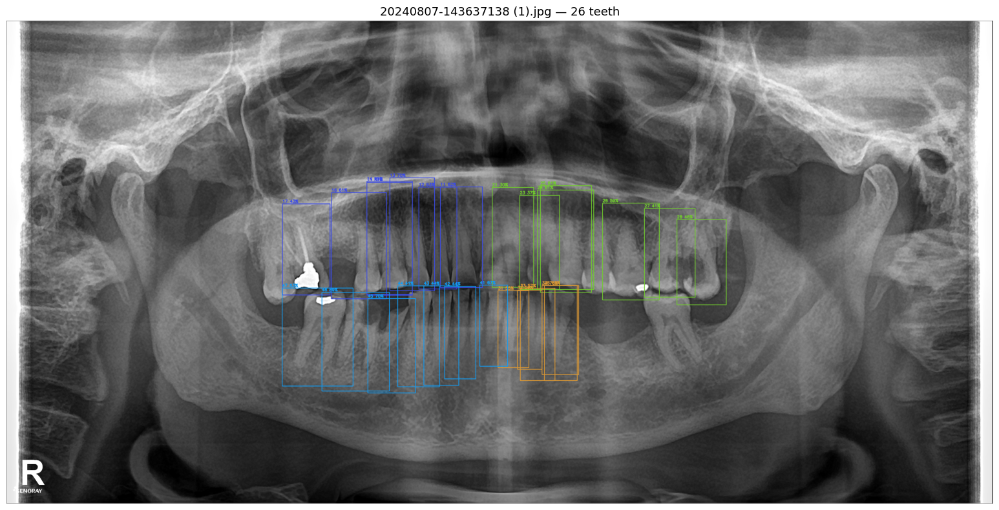


20231031-110753522 (1).jpg
  Total unique teeth: 28
  Q1 Upper Right : 7 -> ['11', '12', '13', '14', '15', '16', '17']  missing=['18']
  Q2 Upper Left  : 6 -> ['21', '23', '24', '25', '26', '27']  missing=['22', '28']
  Q3 Lower Left  : 8 -> ['31', '32', '33', '34', '35', '36', '37', '38']  missing=[]
  Q4 Lower Right : 7 -> ['41', '42', '43', '44', '45', '46', '47']  missing=['48']
  Flagged (same FDI predicted twice, lower-confidence copy dropped):
    13  conf=0.46  bbox=[1767, 766, 1943, 1180]
    31  conf=0.41  bbox=[2077, 1289, 2235, 1704]
    12  conf=0.40  bbox=[1877, 777, 2116, 1275]
    46  conf=0.38  bbox=[915, 1096, 1289, 1521]
    11  conf=0.29  bbox=[1905, 799, 2114, 1272]
    16  conf=0.25  bbox=[1397, 855, 1564, 1203]


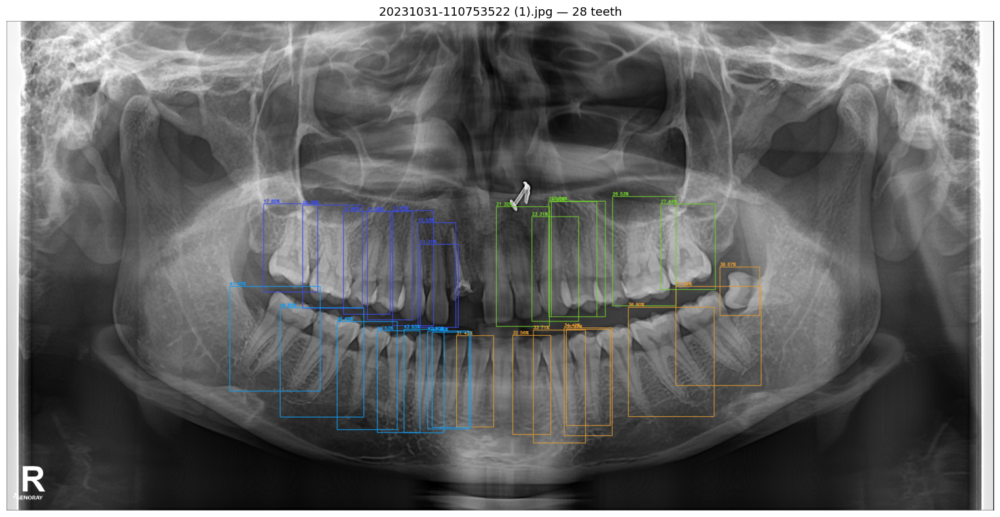


20251222-130038451 (1).jpg
  Total unique teeth: 27
  Q1 Upper Right : 6 -> ['11', '13', '14', '15', '16', '17']  missing=['12', '18']
  Q2 Upper Left  : 7 -> ['21', '22', '24', '25', '26', '27', '28']  missing=['23']
  Q3 Lower Left  : 7 -> ['31', '32', '33', '34', '36', '37', '38']  missing=['35']
  Q4 Lower Right : 7 -> ['41', '42', '43', '44', '45', '46', '47']  missing=['48']
  Flagged (same FDI predicted twice, lower-confidence copy dropped):
    46  conf=0.72  bbox=[1007, 955, 1365, 1411]
    17  conf=0.42  bbox=[901, 506, 1128, 850]
    16  conf=0.42  bbox=[1356, 532, 1525, 969]
    37  conf=0.36  bbox=[3023, 911, 3290, 1341]
    44  conf=0.30  bbox=[1691, 1109, 1881, 1582]
    14  conf=0.29  bbox=[1653, 627, 1857, 1062]
    47  conf=0.26  bbox=[1040, 947, 1375, 1383]
    37  conf=0.26  bbox=[2779, 963, 3068, 1380]


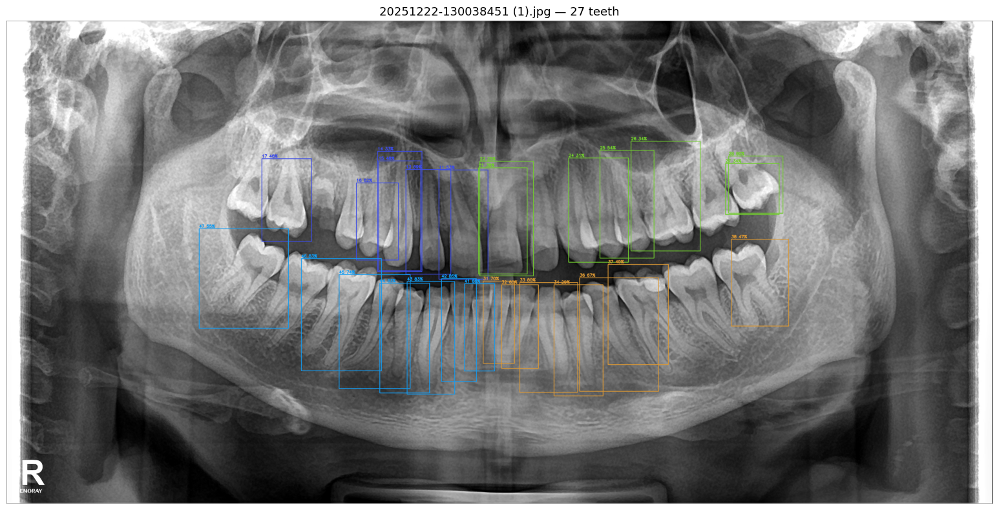


20230814-131806921 (1).jpg
  Total unique teeth: 24
  Q1 Upper Right : 6 -> ['11', '13', '14', '15', '16', '17']  missing=['12', '18']
  Q2 Upper Left  : 6 -> ['21', '24', '25', '26', '27', '28']  missing=['22', '23']
  Q3 Lower Left  : 5 -> ['31', '32', '33', '34', '37']  missing=['35', '36', '38']
  Q4 Lower Right : 7 -> ['41', '42', '43', '44', '45', '46', '47']  missing=['48']
  Flagged (same FDI predicted twice, lower-confidence copy dropped):
    17  conf=0.46  bbox=[1094, 702, 1313, 1073]
    47  conf=0.45  bbox=[1132, 1092, 1452, 1539]
    21  conf=0.31  bbox=[2121, 677, 2310, 1085]


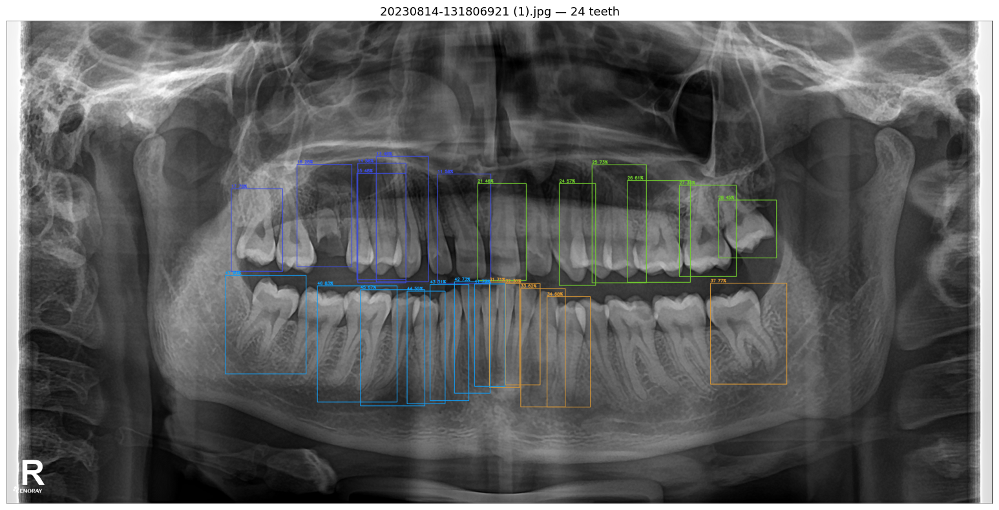


20230821-100210854 (1).jpg
  Total unique teeth: 28
  Q1 Upper Right : 8 -> ['11', '12', '13', '14', '15', '16', '17', '18']  missing=[]
  Q2 Upper Left  : 7 -> ['21', '23', '24', '25', '26', '27', '28']  missing=['22']
  Q3 Lower Left  : 6 -> ['31', '32', '33', '35', '36', '37']  missing=['34', '38']
  Q4 Lower Right : 7 -> ['41', '42', '43', '44', '45', '46', '47']  missing=['48']
  Flagged (same FDI predicted twice, lower-confidence copy dropped):
    12  conf=0.67  bbox=[1706, 755, 1875, 1204]
    25  conf=0.38  bbox=[2555, 764, 2801, 1203]
    41  conf=0.28  bbox=[1835, 1279, 1965, 1698]
    13  conf=0.28  bbox=[1704, 743, 1879, 1207]


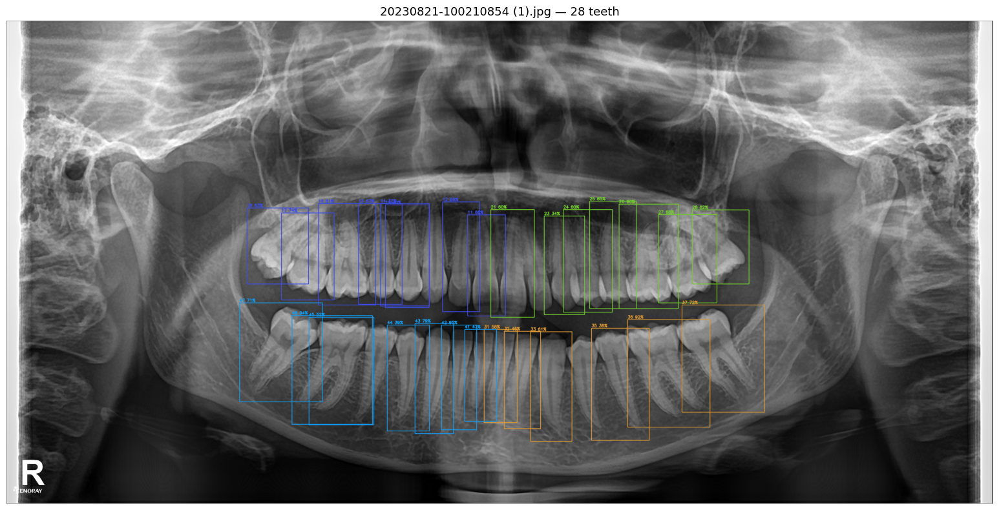


20250805-130531174 (1).jpg
  Total unique teeth: 24
  Q1 Upper Right : 6 -> ['11', '13', '14', '15', '16', '17']  missing=['12', '18']
  Q2 Upper Left  : 6 -> ['21', '24', '25', '26', '27', '28']  missing=['22', '23']
  Q3 Lower Left  : 5 -> ['31', '33', '35', '37', '38']  missing=['32', '34', '36']
  Q4 Lower Right : 7 -> ['41', '42', '43', '44', '45', '46', '47']  missing=['48']
  Flagged (same FDI predicted twice, lower-confidence copy dropped):
    25  conf=0.74  bbox=[2531, 694, 2730, 1166]
    46  conf=0.63  bbox=[1233, 1117, 1564, 1581]
    47  conf=0.52  bbox=[1042, 1090, 1363, 1513]
    16  conf=0.44  bbox=[1167, 681, 1413, 1134]
    26  conf=0.38  bbox=[2798, 724, 3045, 1088]
    15  conf=0.30  bbox=[1465, 727, 1642, 1148]
    27  conf=0.29  bbox=[2821, 768, 3036, 1091]


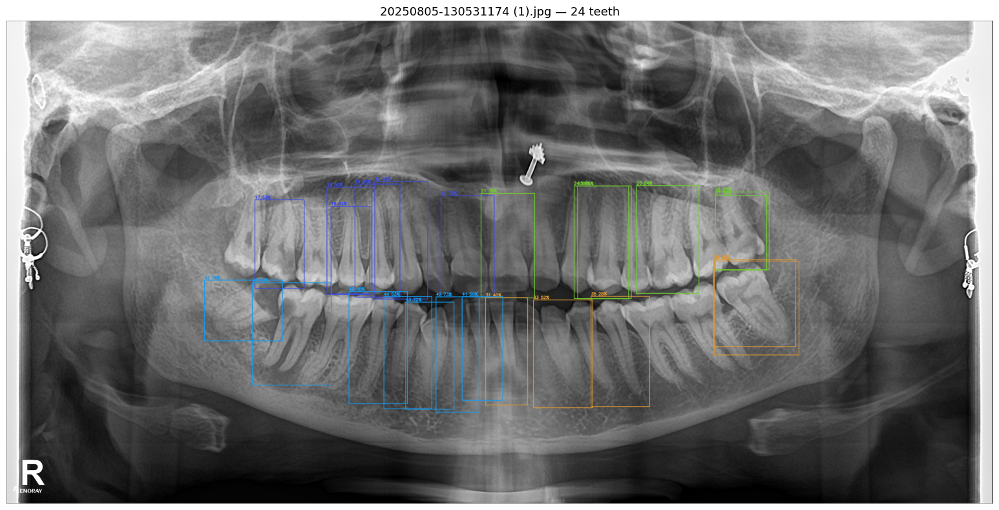

In [ ]:
for img_path in test_images:
    clean, q_teeth, enhanced_path, removed = run_full_pipeline(img_path, model, FDI_CLASSES)
    print_summary(img_path, clean, q_teeth, removed)
    visualize_result(img_path, clean, title=f"{img_path} — {len(clean)} teeth")

In [ ]:
from collections import Counter

names_q = {'1':'Upper Right','2':'Upper Left','3':'Lower Left','4':'Lower Right'}
missing_counter = Counter()
missing_by_quadrant = {'1':Counter(), '2':Counter(), '3':Counter(), '4':Counter()}

for img_path in test_images:
    clean, q_teeth, _, removed = run_full_pipeline(img_path, model, FDI_CLASSES)
    for q in ['1','2','3','4']:
        present = set(q_teeth[q])
        missing = [t for t in FDI_CLASSES if t[0]==q and t not in present]
        for m in missing:
            missing_counter[m] += 1
            missing_by_quadrant[q][m] += 1

print("Most frequently MISSING teeth across all 7 images:")
for fdi, count in missing_counter.most_common(15):
    print(f"  Tooth {fdi}: missing in {count}/{len(test_images)} images")

print("\nMissing count by quadrant:")
for q in ['1','2','3','4']:
    total_missing = sum(missing_by_quadrant[q].values())
    print(f"  Q{q} {names_q[q]:12s}: {total_missing} total missing instances")

Most frequently MISSING teeth across all 7 images:
  Tooth 48: missing in 6/6 images
  Tooth 18: missing in 5/6 images
  Tooth 22: missing in 5/6 images
  Tooth 36: missing in 3/6 images
  Tooth 38: missing in 3/6 images
  Tooth 12: missing in 3/6 images
  Tooth 23: missing in 3/6 images
  Tooth 35: missing in 2/6 images
  Tooth 34: missing in 2/6 images
  Tooth 37: missing in 1/6 images
  Tooth 28: missing in 1/6 images
  Tooth 32: missing in 1/6 images

Missing count by quadrant:
  Q1 Upper Right : 8 total missing instances
  Q2 Upper Left  : 9 total missing instances
  Q3 Lower Left  : 12 total missing instances
  Q4 Lower Right : 6 total missing instances


In [ ]:
def run_pipeline_two_pass(img_path, model, fdi_classes, dedup_iou=0.25):
    """
    Run prediction twice: once at normal confidence (catches most teeth),
    once at a lower confidence (rescues weak upper-jaw detections),
    then merge and dedupe.
    """
    enhanced_path = '/content/temp_enhanced.jpg'
    apply_clahe(img_path, enhanced_path)

    # Pass 1: standard confidence
    res1 = model.predict(enhanced_path, conf=0.25, iou=0.3, imgsz=1280, verbose=False)[0]

    # Pass 2: lower confidence, catches weak/uncertain detections
    res2 = model.predict(enhanced_path, conf=0.12, iou=0.3, imgsz=1280, verbose=False)[0]

    all_detections = []
    for res in [res1, res2]:
        for box in res.boxes:
            fdi = fdi_classes[int(box.cls)]
            all_detections.append({
                'fdi': fdi,
                'confidence': float(box.conf),
                'bbox': [round(v) for v in box.xyxy[0].tolist()],
            })

    spatial_clean = dedupe_same_tooth(all_detections, iou_thresh=dedup_iou)
    final_clean, removed = enforce_unique_fdi(spatial_clean)

    q_teeth = {'1': [], '2': [], '3': [], '4': []}
    for d in final_clean:
        q_teeth[d['fdi'][0]].append(d['fdi'])

    return final_clean, q_teeth, enhanced_path, removed

In [ ]:
# Test the two-pass version on the same images
for img_path in test_images:
    clean, q_teeth, _, removed = run_pipeline_two_pass(img_path, model, FDI_CLASSES)
    print_summary(img_path, clean, q_teeth, removed)


20240807-143637138 (1).jpg
  Total unique teeth: 29
  Q1 Upper Right : 8 -> ['11', '12', '13', '14', '15', '16', '17', '18']  missing=[]
  Q2 Upper Left  : 8 -> ['21', '22', '23', '24', '25', '26', '27', '28']  missing=[]
  Q3 Lower Left  : 6 -> ['31', '32', '33', '34', '35', '37']  missing=['36', '38']
  Q4 Lower Right : 7 -> ['41', '42', '43', '44', '45', '46', '47']  missing=['48']
  Flagged (same FDI predicted twice, lower-confidence copy dropped):
    27  conf=0.41  bbox=[2804, 828, 3017, 1187]
    25  conf=0.40  bbox=[2375, 735, 2567, 1163]
    11  conf=0.29  bbox=[1932, 702, 2109, 1118]
    16  conf=0.25  bbox=[2384, 794, 2561, 1154]
    28  conf=0.24  bbox=[1912, 552, 2089, 758]
    17  conf=0.22  bbox=[1025, 839, 1225, 1203]
    42  conf=0.21  bbox=[1908, 1109, 2027, 1451]
    45  conf=0.16  bbox=[1651, 1113, 1807, 1536]
    16  conf=0.15  bbox=[1524, 780, 1690, 1144]
    22  conf=0.15  bbox=[2037, 730, 2204, 1116]

20231031-110753522 (1).jpg
  Total unique teeth: 30
  Q1 Upp


20240807-143637138 (1).jpg
  Total unique teeth: 29
  Q1 Upper Right : 8 -> ['11', '12', '13', '14', '15', '16', '17', '18']  missing=[]
  Q2 Upper Left  : 8 -> ['21', '22', '23', '24', '25', '26', '27', '28']  missing=[]
  Q3 Lower Left  : 6 -> ['31', '32', '33', '34', '35', '37']  missing=['36', '38']
  Q4 Lower Right : 7 -> ['41', '42', '43', '44', '45', '46', '47']  missing=['48']
  Flagged (same FDI predicted twice, lower-confidence copy dropped):
    27  conf=0.41  bbox=[2804, 828, 3017, 1187]
    25  conf=0.40  bbox=[2375, 735, 2567, 1163]
    11  conf=0.29  bbox=[1932, 702, 2109, 1118]
    16  conf=0.25  bbox=[2384, 794, 2561, 1154]
    28  conf=0.24  bbox=[1912, 552, 2089, 758]
    17  conf=0.22  bbox=[1025, 839, 1225, 1203]
    42  conf=0.21  bbox=[1908, 1109, 2027, 1451]
    45  conf=0.16  bbox=[1651, 1113, 1807, 1536]
    16  conf=0.15  bbox=[1524, 780, 1690, 1144]
    22  conf=0.15  bbox=[2037, 730, 2204, 1116]


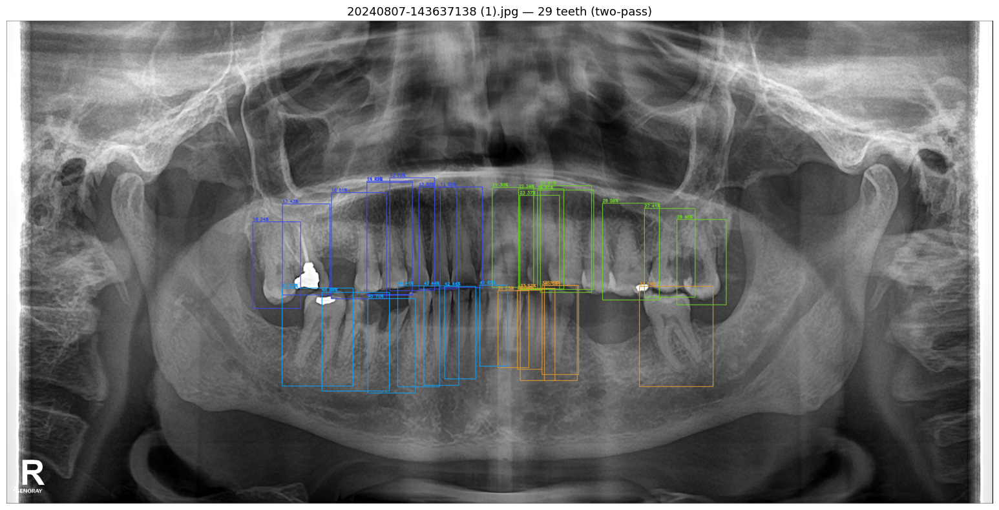


20231031-110753522 (1).jpg
  Total unique teeth: 30
  Q1 Upper Right : 8 -> ['11', '12', '13', '14', '15', '16', '17', '18']  missing=[]
  Q2 Upper Left  : 7 -> ['21', '22', '23', '24', '25', '26', '27']  missing=['28']
  Q3 Lower Left  : 8 -> ['31', '32', '33', '34', '35', '36', '37', '38']  missing=[]
  Q4 Lower Right : 7 -> ['41', '42', '43', '44', '45', '46', '47']  missing=['48']
  Flagged (same FDI predicted twice, lower-confidence copy dropped):
    13  conf=0.46  bbox=[1767, 766, 1943, 1180]
    31  conf=0.41  bbox=[2077, 1289, 2235, 1704]
    12  conf=0.40  bbox=[1877, 777, 2116, 1275]
    46  conf=0.38  bbox=[915, 1096, 1289, 1521]
    11  conf=0.29  bbox=[1905, 799, 2114, 1272]
    16  conf=0.25  bbox=[1397, 855, 1564, 1203]
    35  conf=0.25  bbox=[2420, 1236, 2699, 1688]
    26  conf=0.22  bbox=[2360, 747, 2590, 1210]
    36  conf=0.20  bbox=[2421, 1230, 2693, 1662]
    37  conf=0.19  bbox=[2557, 1176, 2894, 1619]
    37  conf=0.18  bbox=[2418, 1234, 2682, 1656]
    41  c

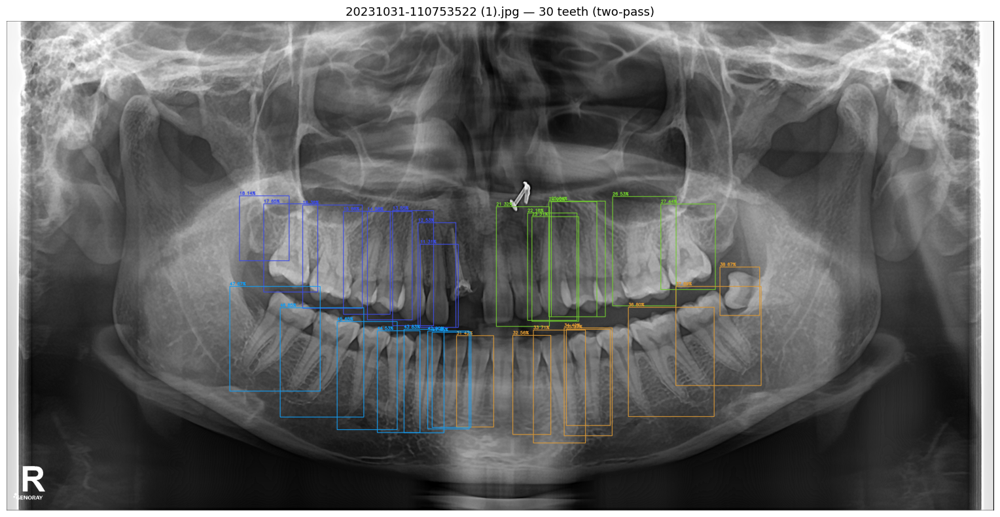


20251222-130038451 (1).jpg
  Total unique teeth: 31
  Q1 Upper Right : 8 -> ['11', '12', '13', '14', '15', '16', '17', '18']  missing=[]
  Q2 Upper Left  : 8 -> ['21', '22', '23', '24', '25', '26', '27', '28']  missing=[]
  Q3 Lower Left  : 8 -> ['31', '32', '33', '34', '35', '36', '37', '38']  missing=[]
  Q4 Lower Right : 7 -> ['41', '42', '43', '44', '45', '46', '47']  missing=['48']
  Flagged (same FDI predicted twice, lower-confidence copy dropped):
    46  conf=0.72  bbox=[1007, 955, 1365, 1411]
    17  conf=0.42  bbox=[901, 506, 1128, 850]
    16  conf=0.42  bbox=[1356, 532, 1525, 969]
    37  conf=0.36  bbox=[3023, 911, 3290, 1341]
    44  conf=0.30  bbox=[1691, 1109, 1881, 1582]
    14  conf=0.29  bbox=[1653, 627, 1857, 1062]
    47  conf=0.26  bbox=[1040, 947, 1375, 1383]
    37  conf=0.26  bbox=[2779, 963, 3068, 1380]
    13  conf=0.23  bbox=[2094, 510, 2331, 1047]
    36  conf=0.15  bbox=[2748, 971, 3108, 1435]
    27  conf=0.15  bbox=[2841, 543, 3077, 902]
    16  conf=0.

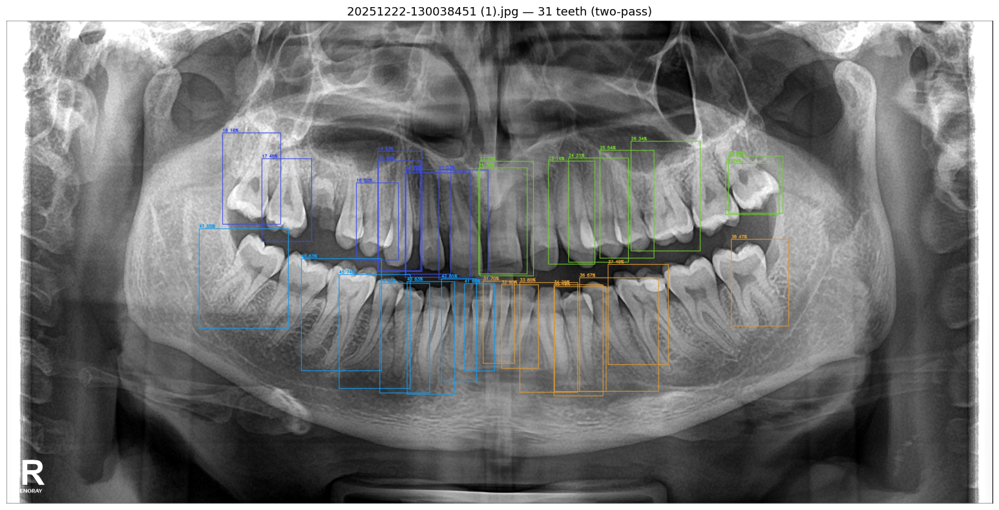


20230814-131806921 (1).jpg
  Total unique teeth: 30
  Q1 Upper Right : 7 -> ['11', '12', '13', '14', '15', '16', '17']  missing=['18']
  Q2 Upper Left  : 8 -> ['21', '22', '23', '24', '25', '26', '27', '28']  missing=[]
  Q3 Lower Left  : 8 -> ['31', '32', '33', '34', '35', '36', '37', '38']  missing=[]
  Q4 Lower Right : 7 -> ['41', '42', '43', '44', '45', '46', '47']  missing=['48']
  Flagged (same FDI predicted twice, lower-confidence copy dropped):
    17  conf=0.46  bbox=[1094, 702, 1313, 1073]
    47  conf=0.45  bbox=[1132, 1092, 1452, 1539]
    21  conf=0.31  bbox=[2121, 677, 2310, 1085]
    44  conf=0.23  bbox=[1499, 1127, 1757, 1605]
    13  conf=0.23  bbox=[1682, 635, 1883, 1085]
    16  conf=0.23  bbox=[1376, 691, 1550, 1072]
    37  conf=0.22  bbox=[2678, 1124, 2983, 1567]
    21  conf=0.21  bbox=[2155, 317, 2324, 687]
    13  conf=0.19  bbox=[1947, 224, 2089, 626]
    11  conf=0.14  bbox=[1977, 622, 2172, 1091]
    36  conf=0.14  bbox=[2491, 1138, 2825, 1638]
    12  conf

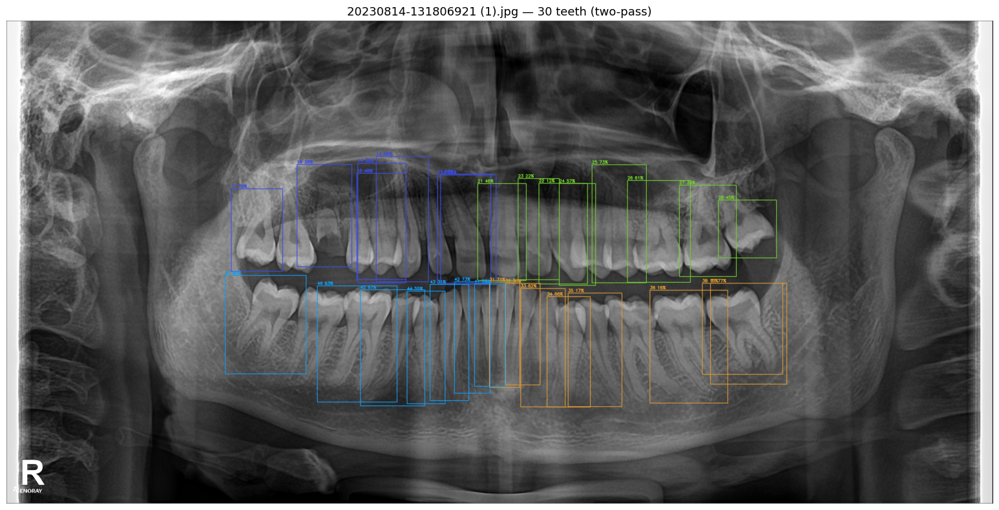


20230821-100210854 (1).jpg
  Total unique teeth: 29
  Q1 Upper Right : 8 -> ['11', '12', '13', '14', '15', '16', '17', '18']  missing=[]
  Q2 Upper Left  : 7 -> ['21', '23', '24', '25', '26', '27', '28']  missing=['22']
  Q3 Lower Left  : 7 -> ['31', '32', '33', '34', '35', '36', '37']  missing=['38']
  Q4 Lower Right : 7 -> ['41', '42', '43', '44', '45', '46', '47']  missing=['48']
  Flagged (same FDI predicted twice, lower-confidence copy dropped):
    12  conf=0.67  bbox=[1706, 755, 1875, 1204]
    25  conf=0.38  bbox=[2555, 764, 2801, 1203]
    41  conf=0.28  bbox=[1835, 1279, 1965, 1698]
    13  conf=0.28  bbox=[1704, 743, 1879, 1207]
    35  conf=0.24  bbox=[2591, 1254, 2917, 1705]
    27  conf=0.22  bbox=[2570, 841, 2813, 1203]
    31  conf=0.19  bbox=[1910, 1262, 2048, 1696]
    16  conf=0.14  bbox=[1878, 396, 1999, 616]
    12  conf=0.13  bbox=[1915, 757, 2085, 1229]
    35  conf=0.13  bbox=[2336, 1315, 2504, 1737]


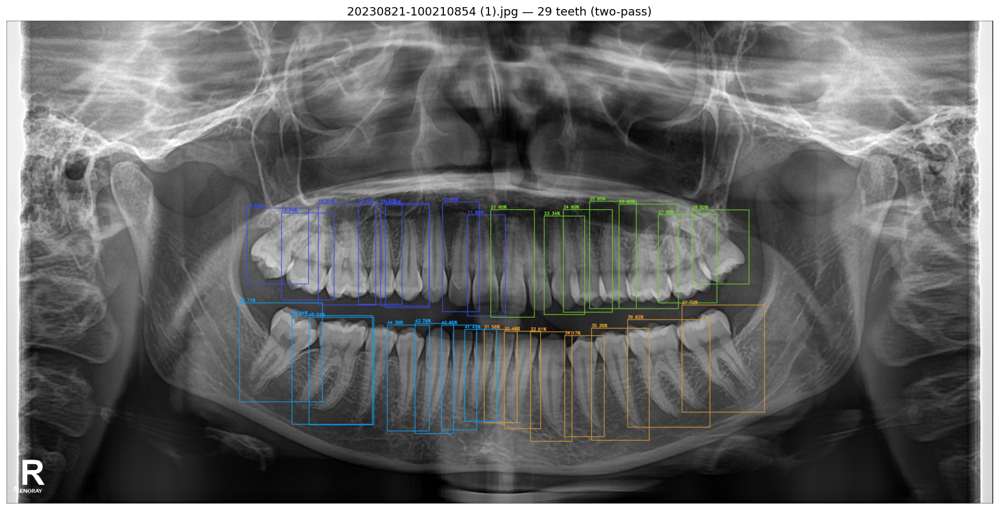


20250805-130531174 (1).jpg
  Total unique teeth: 30
  Q1 Upper Right : 8 -> ['11', '12', '13', '14', '15', '16', '17', '18']  missing=[]
  Q2 Upper Left  : 8 -> ['21', '22', '23', '24', '25', '26', '27', '28']  missing=[]
  Q3 Lower Left  : 7 -> ['31', '32', '33', '35', '36', '37', '38']  missing=['34']
  Q4 Lower Right : 7 -> ['41', '42', '43', '44', '45', '46', '47']  missing=['48']
  Flagged (same FDI predicted twice, lower-confidence copy dropped):
    25  conf=0.74  bbox=[2531, 694, 2730, 1166]
    46  conf=0.63  bbox=[1233, 1117, 1564, 1581]
    47  conf=0.52  bbox=[1042, 1090, 1363, 1513]
    16  conf=0.44  bbox=[1167, 681, 1413, 1134]
    26  conf=0.38  bbox=[2798, 724, 3045, 1088]
    15  conf=0.30  bbox=[1465, 727, 1642, 1148]
    27  conf=0.29  bbox=[2821, 768, 3036, 1091]
    13  conf=0.25  bbox=[1785, 667, 2037, 1149]
    37  conf=0.25  bbox=[2752, 1089, 3064, 1521]
    32  conf=0.20  bbox=[2013, 1161, 2162, 1547]
    18  conf=0.19  bbox=[886, 739, 1106, 1082]
    17  con

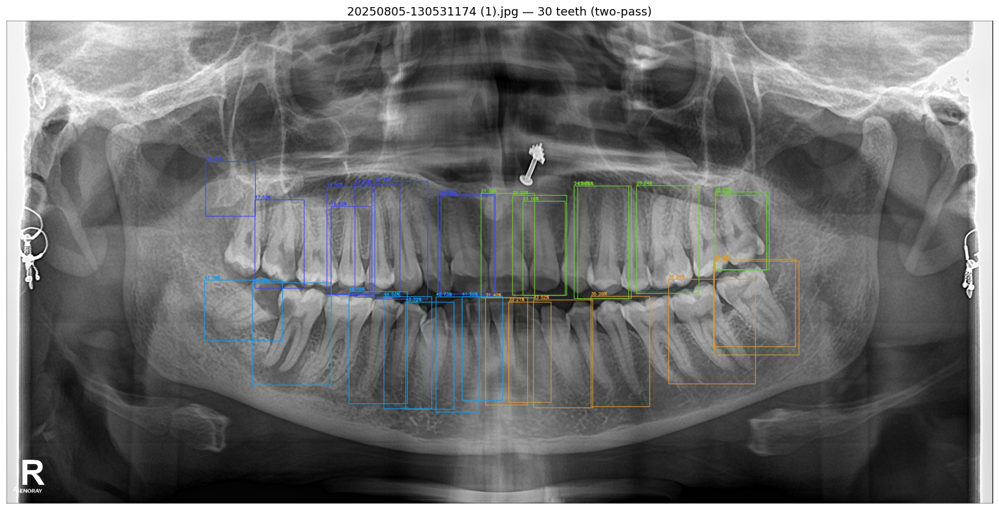

In [ ]:
# Test the two-pass version on the same images — WITH visualization
for img_path in test_images:
    clean, q_teeth, enhanced_path, removed = run_pipeline_two_pass(img_path, model, FDI_CLASSES)
    print_summary(img_path, clean, q_teeth, removed)
    visualize_result(img_path, clean, title=f"{img_path} — {len(clean)} teeth (two-pass)")

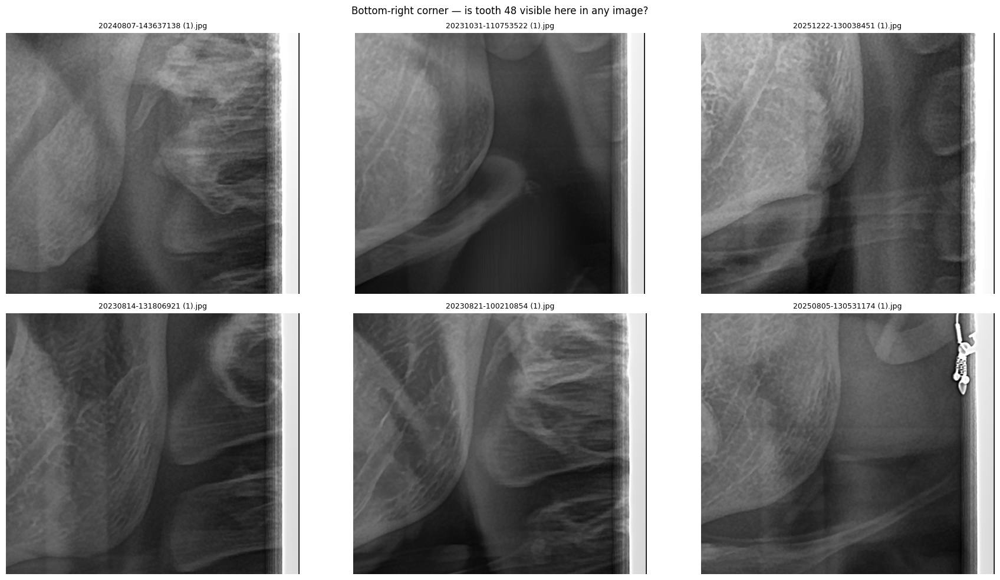

In [ ]:
# Look directly at the bottom-right region (where tooth 48 should be)
# in your enhanced/preprocessed images to see if it's visibly there or genuinely absent
import cv2
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, img_path in zip(axes.flat, test_images):
    img = cv2.imread(img_path)
    h, w = img.shape[:2]
    # Crop bottom-right region (Q4, far right = wisdom tooth area)
    crop = img[int(h*0.45):int(h*0.85), int(w*0.78):w]
    ax.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB), cmap='gray')
    ax.set_title(os.path.basename(img_path), fontsize=9)
    ax.axis('off')
plt.suptitle("Bottom-right corner — is tooth 48 visible here in any image?")
plt.tight_layout()
plt.show()

In [ ]:
import os, glob, cv2, torch, numpy as np
from datetime import datetime
from ultralytics import YOLO

FDI_CLASSES = [
    '11','12','13','14','15','16','17','18',
    '21','22','23','24','25','26','27','28',
    '31','32','33','34','35','36','37','38',
    '41','42','43','44','45','46','47','48',
]

VALIDATED_MODEL = '/content/drive/MyDrive/dental_runs/opg_dentex_v2_noflip/weights/best.pt'
model = YOLO(VALIDATED_MODEL)
print(f"Model loaded: {VALIDATED_MODEL}")

def apply_clahe(img_path, out_path):
    img = cv2.imread(img_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray)
    enhanced_bgr = cv2.cvtColor(enhanced, cv2.COLOR_GRAY2BGR)
    cv2.imwrite(out_path, enhanced_bgr)
    return out_path

def iou(b1, b2):
    x1 = max(b1[0], b2[0]); y1 = max(b1[1], b2[1])
    x2 = min(b1[2], b2[2]); y2 = min(b1[3], b2[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    area1 = (b1[2] - b1[0]) * (b1[3] - b1[1])
    area2 = (b2[2] - b2[0]) * (b2[3] - b2[1])
    union = area1 + area2 - inter
    return inter / union if union > 0 else 0

def dedupe_same_tooth(boxes_list, iou_thresh=0.25):
    boxes_list = sorted(boxes_list, key=lambda x: -x['confidence'])
    final = []
    for d in boxes_list:
        is_dup = any(
            f['fdi'] == d['fdi'] and iou(f['bbox'], d['bbox']) > iou_thresh
            for f in final
        )
        if not is_dup:
            final.append(d)
    return final

def enforce_unique_fdi(detections):
    best_per_fdi = {}
    removed = []
    for d in sorted(detections, key=lambda x: -x['confidence']):
        fdi = d['fdi']
        if fdi not in best_per_fdi:
            best_per_fdi[fdi] = d
        else:
            removed.append(d)
    final = sorted(best_per_fdi.values(), key=lambda x: int(x['fdi']))
    return final, removed

def run_pipeline(img_path, model, fdi_classes, dedup_iou=0.25):
    enhanced_path = '/content/temp_enhanced.jpg'
    apply_clahe(img_path, enhanced_path)

    res1 = model.predict(enhanced_path, conf=0.25, iou=0.3, imgsz=1280, verbose=False)[0]
    res2 = model.predict(enhanced_path, conf=0.12, iou=0.3, imgsz=1280, verbose=False)[0]

    all_detections = []
    for res in [res1, res2]:
        for box in res.boxes:
            fdi = fdi_classes[int(box.cls)]
            all_detections.append({
                'fdi': fdi,
                'confidence': float(box.conf),
                'bbox': [round(v) for v in box.xyxy[0].tolist()],
            })

    spatial_clean = dedupe_same_tooth(all_detections, iou_thresh=dedup_iou)
    final_clean, removed = enforce_unique_fdi(spatial_clean)

    q_teeth = {'1': [], '2': [], '3': [], '4': []}
    for d in final_clean:
        q_teeth[d['fdi'][0]].append(d['fdi'])

    return final_clean, q_teeth, enhanced_path, removed

print("Pipeline functions ready: run_pipeline, dedupe_same_tooth, enforce_unique_fdi")

Model loaded: /content/drive/MyDrive/dental_runs/opg_dentex_v2_noflip/weights/best.pt
Pipeline functions ready: run_pipeline, dedupe_same_tooth, enforce_unique_fdi


In [ ]:
all_results = {}
for img_path in test_images:
    clean, q_teeth, enhanced_path, removed = run_pipeline(img_path, model, FDI_CLASSES)
    all_results[img_path] = (clean, q_teeth, enhanced_path, removed)

print(f"Rebuilt all_results for {len(all_results)} images")

Rebuilt all_results for 6 images


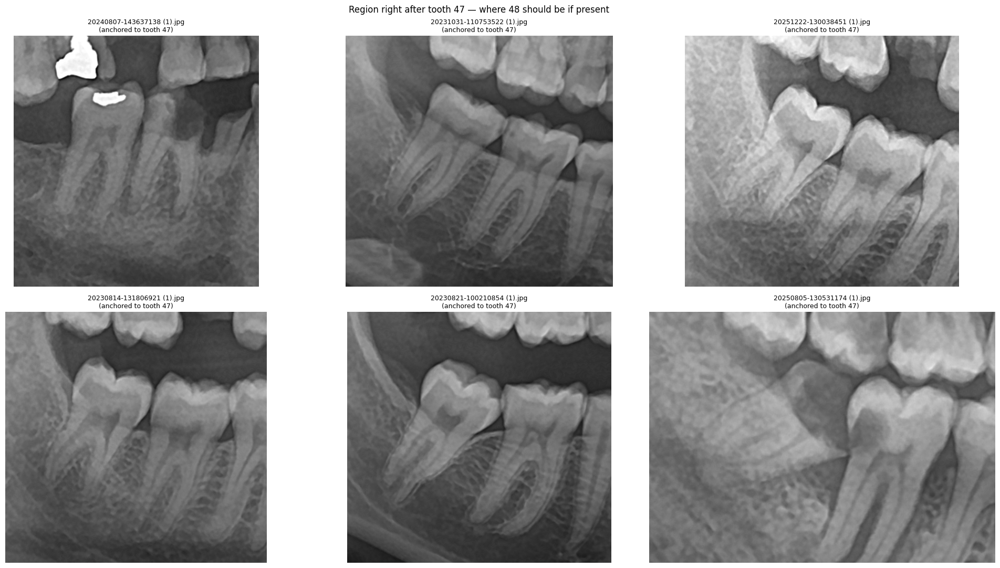

In [ ]:
import cv2
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(20, 11))
for ax, img_path in zip(axes.flat, test_images):
    clean, q_teeth, enhanced_path, removed = all_results[img_path]
    img = cv2.imread(img_path)
    h, w = img.shape[:2]

    # Find where tooth 47 (next to 48) actually landed, to anchor the crop correctly
    tooth_47 = next((d for d in clean if d['fdi'] == '47'), None)

    if tooth_47:
        x1, y1, x2, y2 = tooth_47['bbox']
        # Crop a wider region extending right and around from tooth 47's position
        crop_x1 = max(0, x1 - 50)
        crop_x2 = min(w, x2 + 250)
        crop_y1 = max(0, y1 - 100)
        crop_y2 = min(h, y2 + 100)
        crop = img[crop_y1:crop_y2, crop_x1:crop_x2]
        ax.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB), cmap='gray')
        ax.set_title(f"{os.path.basename(img_path)}\n(anchored to tooth 47)", fontsize=9)
    else:
        ax.text(0.5, 0.5, "Tooth 47 not found either", ha='center', va='center')
        ax.set_title(os.path.basename(img_path), fontsize=9)
    ax.axis('off')

plt.suptitle("Region right after tooth 47 — where 48 should be if present")
plt.tight_layout()
plt.show()

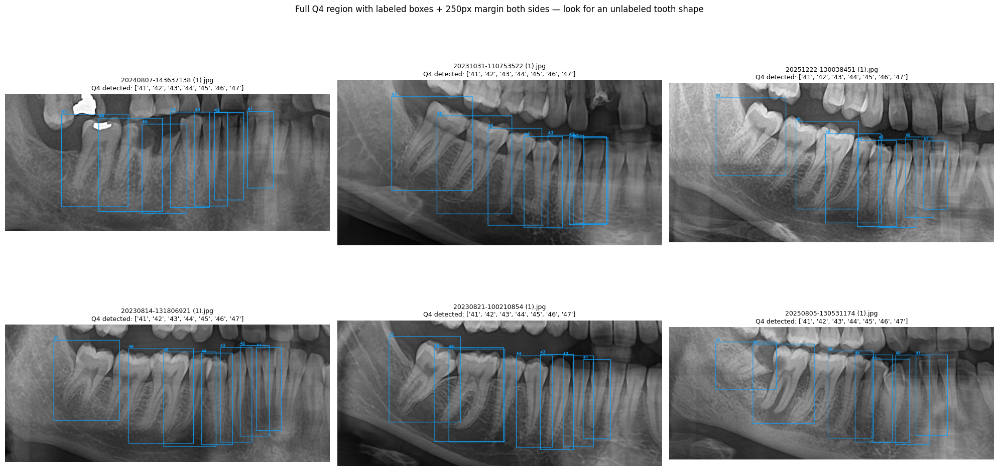

In [ ]:
import cv2
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(20, 11))

for ax, img_path in zip(axes.flat, test_images):
    clean, q_teeth, enhanced_path, removed = all_results[img_path]
    img = cv2.imread(img_path)
    h, w = img.shape[:2]

    # Get all Q4 (lower right) detections to find the real span of that quadrant
    q4_dets = [d for d in clean if d['fdi'][0] == '4']

    if q4_dets:
        # Find the bounding region covering ALL Q4 teeth, then extend 200px
        # further in BOTH directions so we can't miss an undetected tooth
        all_x1 = min(d['bbox'][0] for d in q4_dets)
        all_x2 = max(d['bbox'][2] for d in q4_dets)
        all_y1 = min(d['bbox'][1] for d in q4_dets)
        all_y2 = max(d['bbox'][3] for d in q4_dets)

        crop_x1 = max(0, all_x1 - 250)
        crop_x2 = min(w, all_x2 + 250)
        crop_y1 = max(0, all_y1 - 80)
        crop_y2 = min(h, all_y2 + 80)

        crop = img[crop_y1:crop_y2, crop_x1:crop_x2].copy()

        # Draw the actual detected boxes on this crop, shifted to crop coords
        for d in q4_dets:
            x1, y1, x2, y2 = d['bbox']
            cv2.rectangle(crop, (x1-crop_x1, y1-crop_y1), (x2-crop_x1, y2-crop_y1),
                         (243, 156, 18), 2)
            cv2.putText(crop, d['fdi'], (x1-crop_x1, max(15, y1-crop_y1-5)),
                       cv2.FONT_HERSHEY_SIMPLEX, 0.6, (243, 156, 18), 2)

        ax.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{os.path.basename(img_path)}\nQ4 detected: {sorted([d['fdi'] for d in q4_dets], key=int)}",
                    fontsize=9)
    else:
        ax.text(0.5, 0.5, "No Q4 detections at all", ha='center', va='center')
        ax.set_title(os.path.basename(img_path), fontsize=9)
    ax.axis('off')

plt.suptitle("Full Q4 region with labeled boxes + 250px margin both sides — look for an unlabeled tooth shape")
plt.tight_layout()
plt.show()